In [1]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]



if "mimi" in hostname or "pingo" in hostname or "ivan" in hostname:
    DATA_DIR = "/mn/vann/franzihe/"
    FIG_DIR = "/uio/kant/geo-geofag-u1/franzihe/Documents/Figures/ANX_obs_daily/final/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
OUTPUT_DATA_DIR = os.path.join(DATA_DIR, 'output')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass



ivan.uio.no


In [2]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt, np, DateFormatter, DayLocator, datetime, cm, pd, da, IMProToo,LinearSegmentedColormap, BoundaryNorm, time, curve_fit, sns, set_context, linregress, pi, Rectangle, HandlerTuple, Line2D, ListedColormap, Patch, fnmatch)
# from matplotlib.collections import PathCollection
import functions as fct
version = IMProToo.__version__


In [3]:
# plot cosmetics
set_context('paper', rc={"lines.linewidth": 2}, font_scale=1.5, )

In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
site = 'ANX'
year = '2023'

### Files to read in

In [6]:
ds_23 = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_0_0.0', f'10min_filled_obs_hatpro_airport_WD_WS_T_{site}_{year}*.nc'))))#[['Ze', 'W', 'height', 'air_temperature', 'precipitation', 'wind_direction', 'wind_speed', 'Matrosov_a_400', 'Bracci_a_400','Pu_g_400','Ze_400m']]
ds_23 = ds_23.rename_vars({'precipitation':'Geonor'})

In [7]:
# List all files
file_paths = sorted(glob(os.path.join(OUTPUT_DATA_DIR, f'ANX_obs_EM_*', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc')))
# open all datasets individually first
datasets = [xr.open_dataset(file_path) for file_path in file_paths]
# combine them 
combined_dataset = xr.combine_by_coords(datasets, compat='override')


# -----
vars_to_keep = ["Geonor", #"air_temperature", "wind_direction", "wind_speed", 
"snowflake_class_name_60", "snowflake_class_name_70", "snowflake_class_name_80", "rate_mm_h", "start_time", "delta_h", "fallspeed", "W_400m"
#"flake_Dmax", "gan3d_mass"
]
# -----

pattern = "*_400_mm_h"
# filter variables based on pattern
filtered_vars = [v for v in combined_dataset if fnmatch.fnmatch(v, pattern)]
vars_to_keep = vars_to_keep+filtered_vars
# select only chosen variables
ds_subset = combined_dataset[vars_to_keep]


In [8]:
df_event_offset = ds_subset.to_dataframe().dropna()

In [9]:
met = combined_dataset[["air_temperature", "wind_direction", "wind_speed", "flake_Dmax", "gan3d_mass"]].to_dataframe()
df_event_offset = pd.concat([df_event_offset, met.loc[df_event_offset.index]], axis=1)

### Histogram of event duration

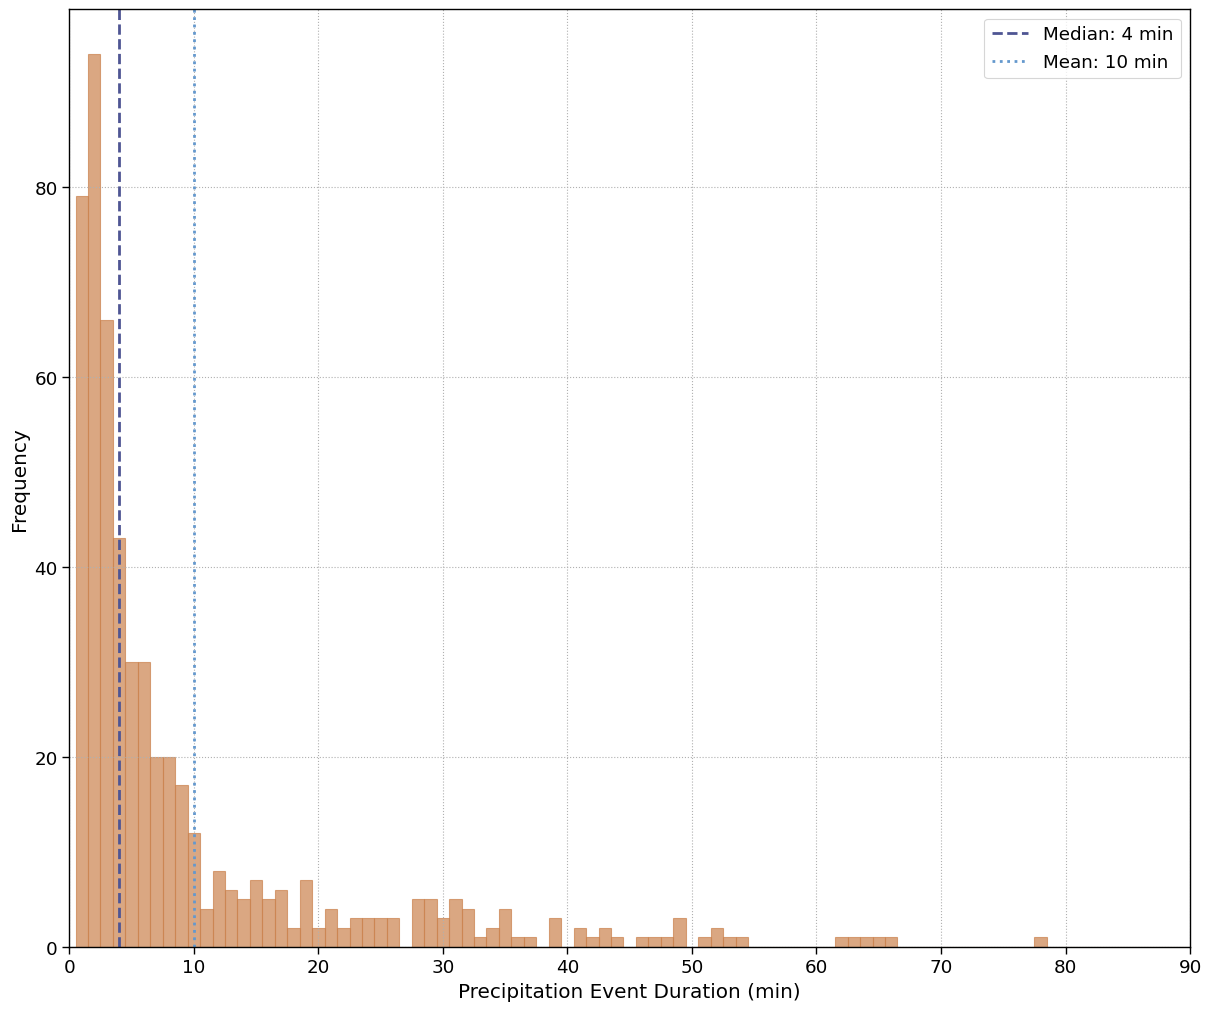

In [10]:
median_delta_h = (df_event_offset['delta_h']*60).median().round(0)
mean_delta_h = (df_event_offset['delta_h']*60).mean().round(0)
fig, axs = plt.subplots(1, 1, figsize=(12,10), constrained_layout=True, sharex=True)

n, bins, _ = axs.hist(df_event_offset.delta_h*60, bins=np.arange(0,92), color=fct.custom_colors['aggregate'],alpha=0.7,histtype='bar', edgecolor=fct.custom_colors['aggregate'], align='left')
axs.set_xlim([0, 90])

# Add a vertical line for the median
axs.axvline(
    median_delta_h,
    color=fct.custom_colors['graupel'],
    linestyle="dashed",
    linewidth=2,
    label=f"Median: {median_delta_h:.0f} min",
)
axs.axvline(
    mean_delta_h,
    color=fct.custom_colors['pristine'],
    linestyle="dotted",
    linewidth=2,
    label=f"Mean: {mean_delta_h:.0f} min",
)

# Add titles, labels, and legend
# plt.title("Data Histogram with Median Line")
plt.xlabel("Precipitation Event Duration (min)")
plt.ylabel("Frequency")
plt.legend()

axs.grid(which='major', axis='x', linestyle=':')
axs.grid(which='minor', axis='x', linestyle=':', alpha=0.3)
axs.grid(which='major', axis='y', linestyle=':')
axs.grid(which='minor', axis='y', linestyle=':', alpha=0.3)

plt.savefig(FIG_DIR + 'precip_event_duration.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

### Compare fall speed MRR to MASC

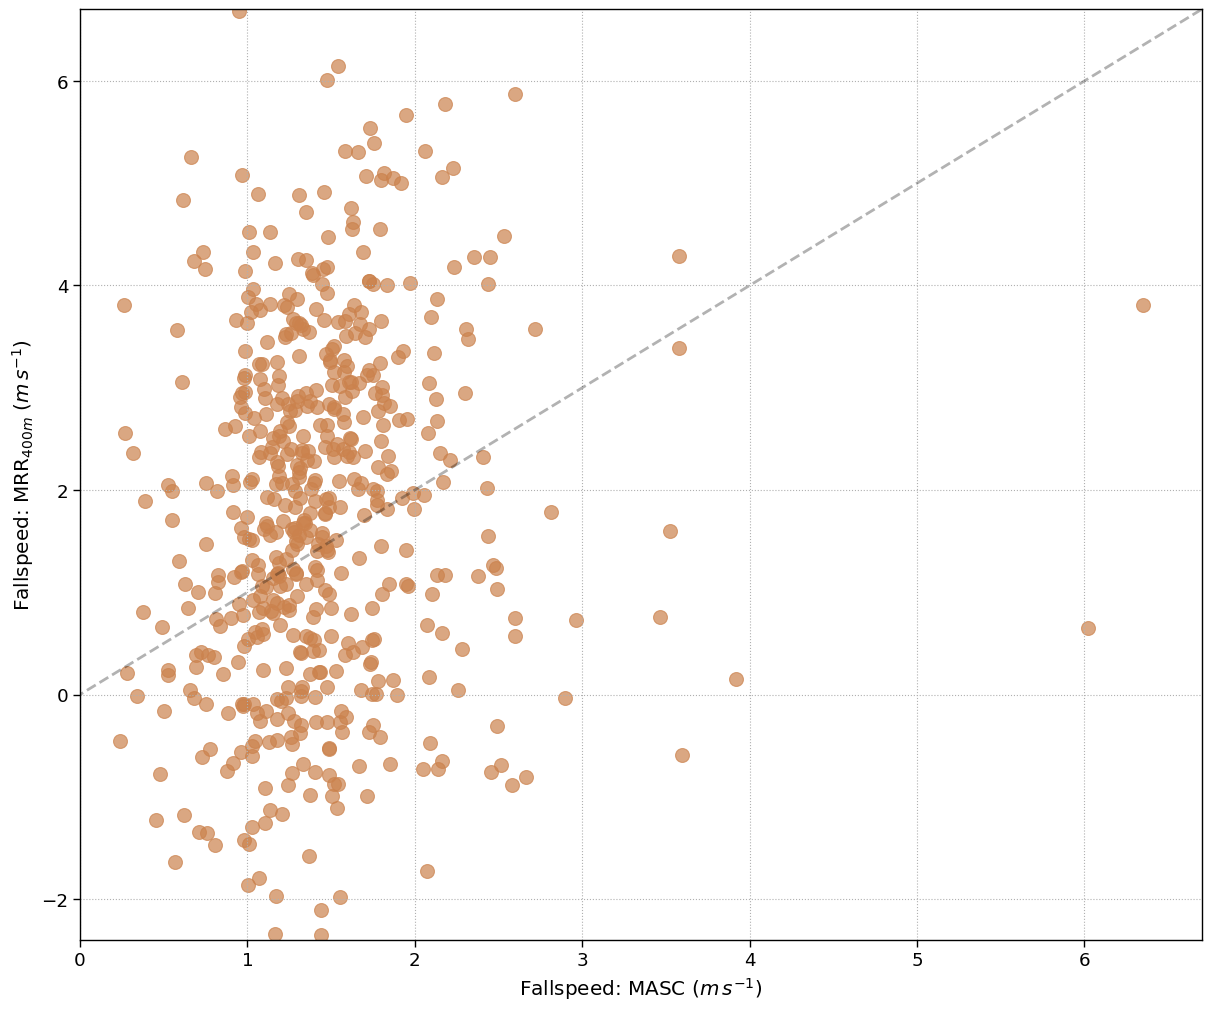

In [11]:
fig, axs = plt.subplots(1, 1, figsize=(12,10), constrained_layout=True, sharex=True)

df_event_offset.plot.scatter(ax=axs, x='fallspeed', y='W_400m',color=fct.custom_colors['aggregate'],alpha=0.7, edgecolor=fct.custom_colors['aggregate'],s=100)
axs.plot([-2.2, 7], [-2.2,7], color='k', alpha=0.3, linestyle='--')

axs.set_xlim([0, 6.7])
axs.set_ylim([-2.4, 6.7])

# Add titles, labels, and legend
plt.xlabel("Fallspeed: MASC ($m\,s^{-1}$)")
plt.ylabel("Fallspeed: MRR$_{400m}$ ($m\,s^{-1}$)")

axs.grid(which='major', axis='x', linestyle=':')
axs.grid(which='minor', axis='x', linestyle=':', alpha=0.3)
axs.grid(which='major', axis='y', linestyle=':')
axs.grid(which='minor', axis='y', linestyle=':', alpha=0.3)

plt.savefig(FIG_DIR + 'fallspeed_MASC_vs_MRR.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

### Filter the dominant snowflake class and create individual dataframes

In [12]:
# convert wind into [0, 360)
df_event_offset['wind_direction'] = df_event_offset['wind_direction'] % 360
df_event_offset['wind_direction_sector_4'] = pd.cut(df_event_offset['wind_direction'], bins=[0., 45., 135., 225., 315., 360.], labels = ['N', 'E', 'S',  'W', 'N'], include_lowest=True, right=False, ordered=False)

northerly = df_event_offset[df_event_offset['wind_direction_sector_4'] == 'N']
easterly = df_event_offset[df_event_offset['wind_direction_sector_4'] == 'E']
southerly = df_event_offset[df_event_offset['wind_direction_sector_4'] == 'S']
westerly = df_event_offset[df_event_offset['wind_direction_sector_4'] == 'W']

sf_class_dict = {}

sf_class_dict = {'campaign': df_event_offset, 'North': northerly, 'East': easterly, 'South': southerly, 'West': westerly}

In [11]:

for sf_class in ['aggregate', 'graupel', 'mixed', 'pristine']:
    for thrs in [60, 70, 80]:
        sf_class_dict[f'{sf_class}_{thrs}'] = df_event_offset[df_event_offset[f'snowflake_class_name_{thrs}'] == sf_class]
        print(sf_class, thrs, len(sf_class_dict[f'{sf_class}_{thrs}']), len(df_event_offset[df_event_offset[f'snowflake_class_name_{thrs}'] == sf_class]))
for thrs in [60, 70, 80]:
    # campaign stays seperate
    indexes_to_exclude = sf_class_dict[f'pristine_{thrs}'].index
    sf_class_dict[f'campaign_{thrs}'] = df_event_offset.loc[~df_event_offset.index.isin(indexes_to_exclude)]
    if thrs == 80:
        df_event_offset = df_event_offset.loc[~df_event_offset.index.isin(indexes_to_exclude)]
    del sf_class_dict[f'pristine_{thrs}']


aggregate 60 62 62
aggregate 70 37 37
aggregate 80 23 23
graupel 60 360 360
graupel 70 294 294
graupel 80 240 240
mixed 60 114 114
mixed 70 205 205
mixed 80 273 273
pristine 60 3 3
pristine 70 3 3
pristine 80 3 3


## Campaign overview

In [12]:
day_start = df_event_offset.index.min().normalize()
day_end = df_event_offset.index.max().normalize() + pd.Timedelta('1D')
ds_season = ds_23.sel(time=slice(day_start, day_end))

# get the “no MASC available” timestamps
all_times = ds_23['time'].values
masc_times = df_event_offset.index
# threshold one day
# threshold = pd.Timedelta('1440min')

# Step 1: sort (just to be safe)
masc_times = masc_times.sort_values()
masc_series = masc_times.to_series()

# Step 2: compute the gaps between consecutive MASC timesteps
deltat = masc_times.diff()
# mask for large gaps # threshold one day
gap_mask = deltat > pd.Timedelta('1440min')

# Step 3: find where the gap exceeds threshold
# gap_starts = masc_times[deltat > threshold] # first timestamp *after* a long gap
gap_ends = masc_series[gap_mask]

# gap_ends = gap_starts - deltat[deltat > threshold] # last timestamp *before* the gap
gap_starts = masc_series.shift(1)[gap_mask]

gaps = list(zip(gap_starts.values, gap_ends.values))
gaps = [
    (start, end)
    for start, end in zip(gap_starts, gap_ends)
    if pd.notna(start) and pd.notna(end)
]

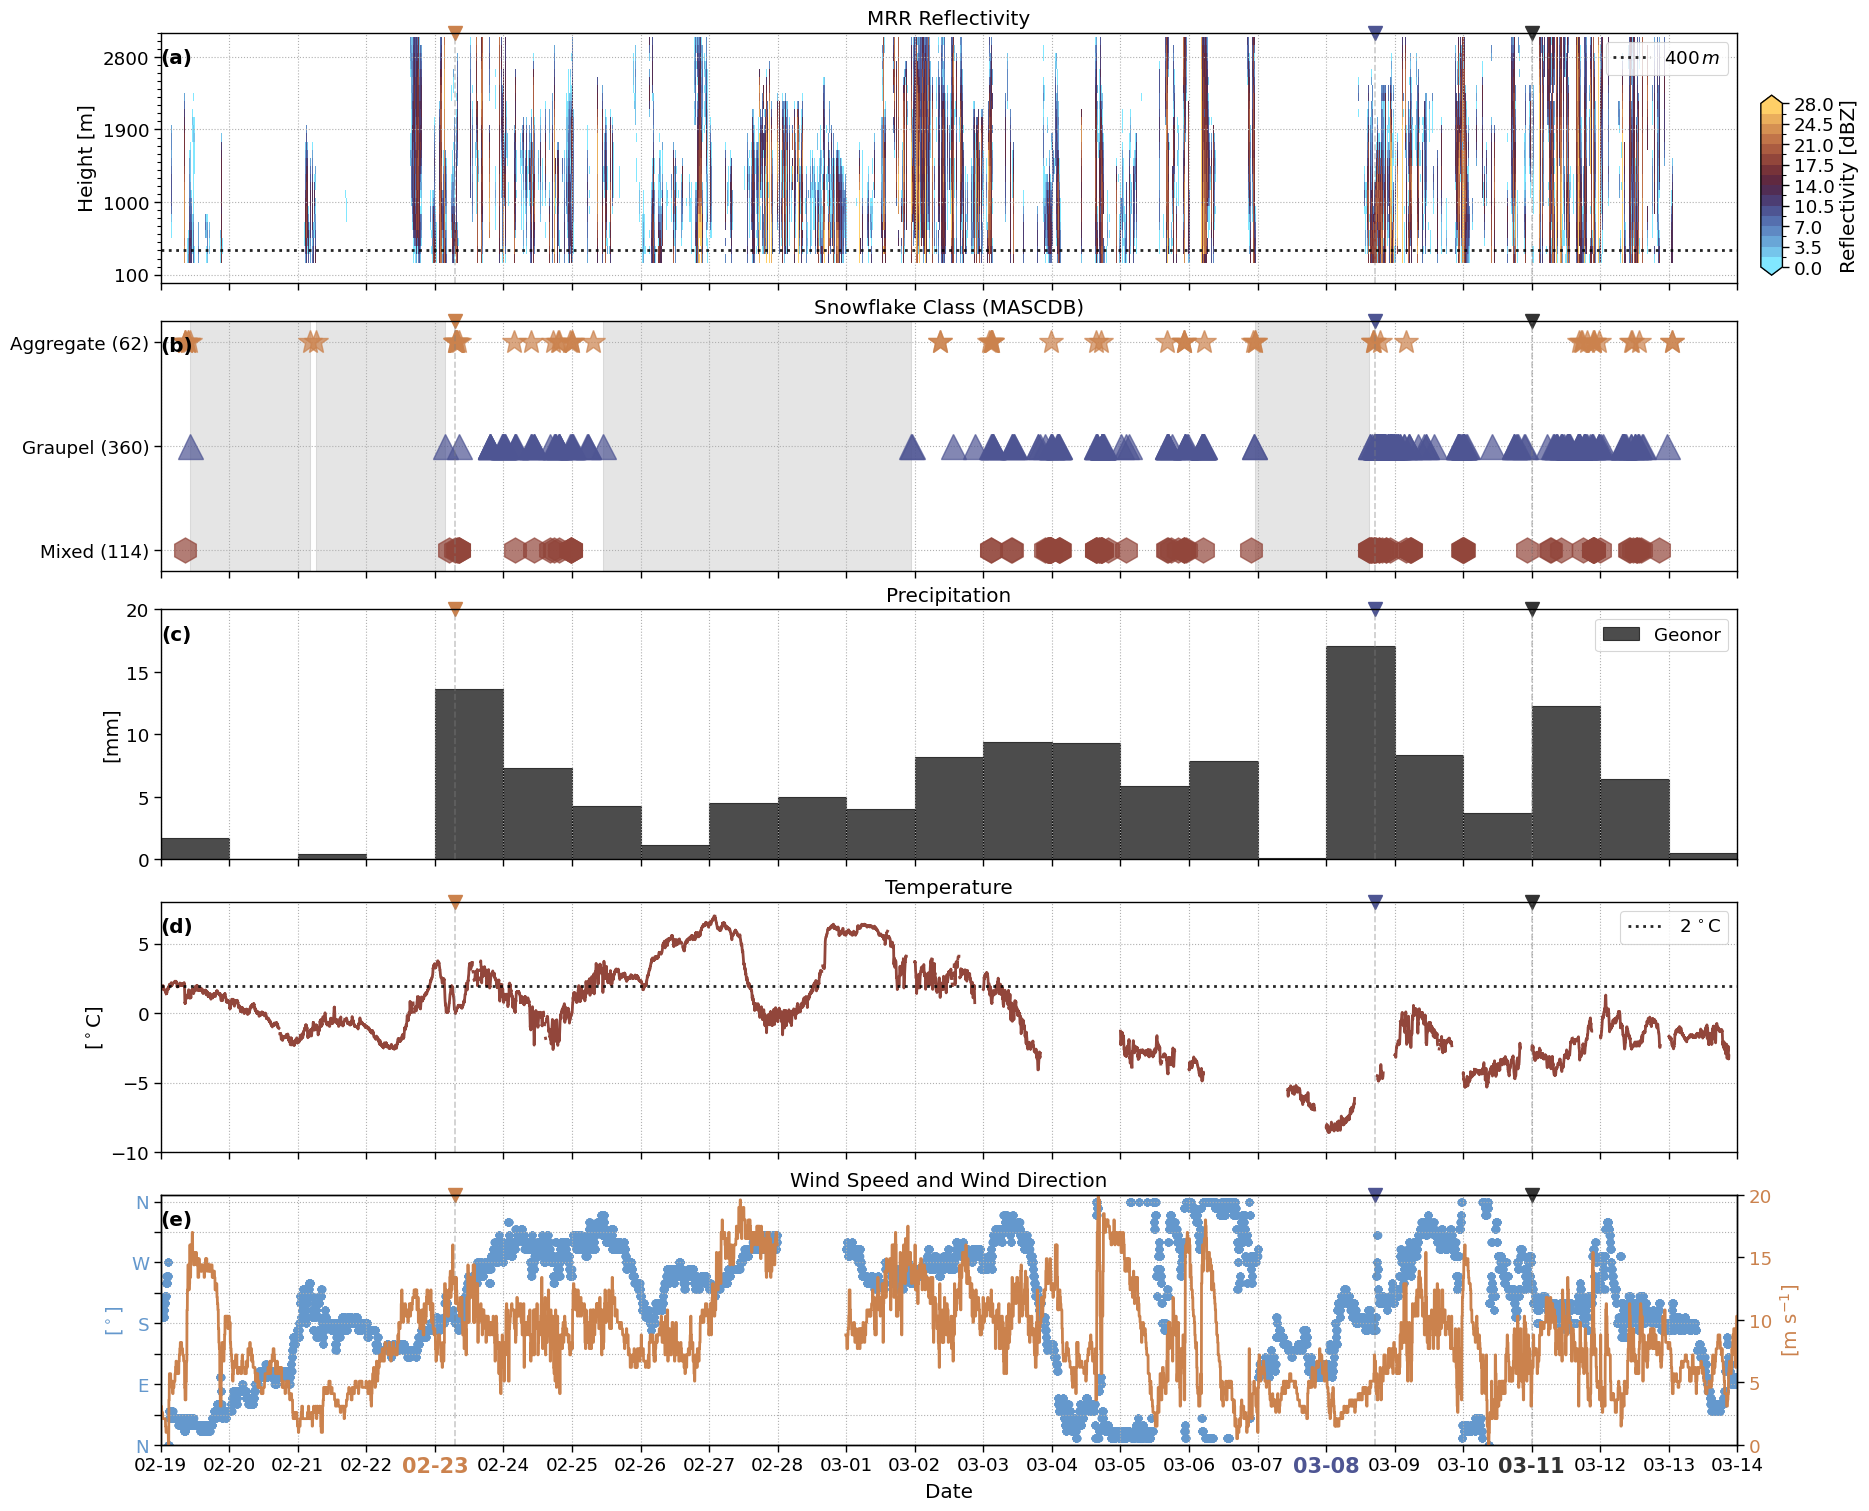

In [13]:
# Define your case study dates
case_dates = [
    pd.Timestamp("2023-02-23 07:00"),
    pd.Timestamp("2023-03-08 17:00"),
    pd.Timestamp("2023-03-11"),
]

case_dates_num = fct.date2num(case_dates)

case_colors = [
    fct.custom_colors['aggregate'],
    fct.custom_colors['graupel'],
    '0.2'
]


fig, axsm = plt.subplots(5, 1, figsize=(18,15), constrained_layout=True, sharex=True)
axs = axsm.flatten()


bounds = np.linspace(0,28, 17)
norm=BoundaryNorm(boundaries=bounds, ncolors=256)
# ------ plot reflectivity ----
time_vals = fct.date2num(ds_season['time'].values)
range_vals = ds_season['range'].values
Ze_vals = ds_season['Ze'].values.T
# Ze_vals = ds_season['Ze_linear'].values.T
fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=Ze_vals, x=time_vals, y=range_vals, cmap=cm.managua_r, norm=norm, cbar_bounds=bounds[::2], cbar_label="Reflectivity [dBZ]", cbar_pos=[0.975, 0.82, 0.012, 0.12])
axs[0].hlines(4., time_vals[0], time_vals[-1], colors='k', linestyles=':', alpha=0.85, label='$400\,m$')
axs[0].legend(loc='upper right')

# axs[0].set_yticks(range_vals[::9])
# axs[0].set_yticklabels(range_vals[::9]*100)
yticks = range_vals[::9]
axs[0].set_yticks(yticks)
axs[0].set_yticklabels((yticks * 100).astype(int))  # removes .0

# minor ticks (every bin)
axs[0].set_yticks(range_vals, minor=True)
axs[0].tick_params(axis='y', which='minor', length=3)

axs[0].set_ylim(0, range_vals.max())
axs[0].set_ylabel("Height [m]")
# ----------------------------
# # Add arrows for case studies
# for x in case_dates_num:
#     axs[0].annotate(
#         '', 
#         xy=(x, 2500),        # arrow tip (adjust height if needed)
#         xytext=(x, 3000),    # arrow start (top)
#         arrowprops=dict(color='red', arrowstyle='-|>', lw=2)
#     )
# # Add labels for case studies
# labels = ["23 Feb", "8 Mar", "11 Mar"]

# for x, label in zip(case_dates_num, labels):
#     axs[0].annotate(
#         label,
#         xy=(x, 3000),
#         xytext=(x, 3100),
#         color='red',
#         ha='center',
#         fontsize=10,
#         rotation=90
#     )

# ------ dominant habit ----
order = [#'pristine', 
'mixed', 'graupel', 'aggregate']
keys = [f"{name}_60" for name in order]

habit_counts=[]
markers = [#'o', 
'h', '^', '*',]
for y_pos, (name, key) in enumerate(zip(order, keys)):
    habit = sf_class_dict[key]['snowflake_class_name_60']
    time_vals = fct.date2num(habit.index)
    y_vals = np.full(len(habit), y_pos)

    habit_counts.append(len(habit))

    axs[1].plot(
        time_vals,
        y_vals,
        marker=markers[y_pos],
        linestyle='None',
        color=fct.custom_colors[name],
        markersize=18,
        label=name.title(),
        alpha=0.7
    )

axs[1].set_yticks(range(3))
axs[1].set_yticklabels([
    f"{name.title()} ({cnt})"
    for name, cnt in zip(order, habit_counts)
])
axs[1].set_ylim(-0.2, 2.2)
# hightlight the MASC gaps
for g_start, g_end in gaps:
    g_start = fct.date2num(g_start)
    g_end = fct.date2num(g_end)
    axs[1].axvspan(g_start, g_end, color='k', alpha=0.1)
# ----------------------------

# ------ precipitation accumulation ----
precip = ds_season['Geonor'].resample(time='24H', closed='right', label='right').sum()
time_vals = fct.date2num(precip['time'].values)
axs[2].bar(time_vals, precip, width=-1., align='edge', color="k", label="Geonor", alpha=0.7, edgecolor='k') # use align='center', the bar will be centered on the midnight timestamp, which visually still represents the day ending at that time.
axs[2].set_ylabel("[mm]")
axs[2].legend()
axs[2].set_ylim([0, 20])
# ----------------------------

# ------ near surface air temperature ----
temp = ds_season['air_temperature']
time_vals = fct.date2num(temp['time'].values)
axs[3].plot(time_vals, temp, color=fct.custom_colors['mixed'])
axs[3].hlines(2., time_vals[0], time_vals[-1], colors='k', alpha=0.85, linestyle=':', label="$2\,^\circ$C")
axs[3].set_ylabel("[$^\circ$C]")
axs[3].set_ylim([-10, 8])
axs[3].legend()
# ----------------------------

# ------ 10m wind ----
wd = ds_season['wind_direction']
time_vals = fct.date2num(wd['time'].values)
axs[4].scatter(time_vals, wd.values, color=fct.custom_colors['pristine'])
axs[4].set_ylabel("[$^\circ$]", color=fct.custom_colors['pristine'])
axs[4].tick_params(axis='y', labelcolor=fct.custom_colors['pristine'])
axs[4].set_ylim(0,370)
axs[4].set_yticks(np.arange(0,365,45))
axs[4].set_yticklabels(['N', '', 'E', '' , 'S', '', 'W', '', 'N'])

ws = ds_season['wind_speed']
time_vals = fct.date2num(ws['time'].values)
ax2 = axs[4].twinx()
ax2.plot(time_vals, ws.values, color=fct.custom_colors['aggregate'])
ax2.set_ylabel('[m s$^{-1}$]', color=fct.custom_colors['aggregate'])
ax2.tick_params(axis='y', labelcolor=fct.custom_colors['aggregate'])
ax2.set_ylim(0,20)
# ----------------------------

# ------ formatting ----
major_locator = DayLocator(interval=1)   # label every 2 days 
# minor_locator = DayLocator(interval=1)   # tick every day
date_form = DateFormatter("%m-%d")       # no year
for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Precipitation", "Temperature", "Wind Speed and Wind Direction"]):
    ax.set(title=title)
    ax.text(0.01, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)

    ax.xaxis.set_major_locator(major_locator)
    # ax.xaxis.set_minor_locator(minor_locator)
    ax.xaxis.set_major_formatter(date_form)

    ax.grid(which='major', axis='x', linestyle=':')
    ax.grid(which='minor', axis='x', linestyle=':', alpha=0.3)

    if i in [0, 1, 3, 4]:
        ax.yaxis.grid(ls=':')

    ax.tick_params(axis='x', labelrotation=0)
    plt.setp(ax.get_xticklabels(), horizontalalignment="center")

    ax.set_xlim([day_start, day_end])
# recolor case study tick labels
case_dates_str = [d.strftime("%m-%d") for d in case_dates]
date_color_map = dict(zip(case_dates_str, case_colors))

for ax in axs:
    for label in ax.get_xticklabels():
        txt = label.get_text()
        if txt in date_color_map:
            label.set_color(date_color_map[txt])
            label.set_fontweight('bold')
            label.set_fontsize(15)
            # label.set_alpha(0.8)
            
for ax in axs:
    ax.tick_params(which='minor', length=3)
    ylim = ax.get_ylim()
        
    for x, color in zip(case_dates_num, case_colors):
        ax.plot(x, ylim[1], marker='v', color=color, markersize=10, clip_on=False)
        ax.axvline(x, color='0.5', linestyle='--', alpha=0.4, linewidth=1.2)

    
axs[-1].set(xlabel="Date")
plt.savefig(FIG_DIR + 'fig02.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

In [14]:
ds_season['Geonor'].resample(time='24H', closed='right', label='right').sum().values

array([ 0.        ,  1.74013333,  0.        ,  0.44683333,  0.07426667,
       13.63356667,  7.2957    ,  4.27806667,  1.16086667,  4.50873333,
        4.96906667,  4.0203    ,  8.22763333,  9.41646667,  9.33473333,
        5.8487    ,  7.85493333,  0.08766667, 17.1006    ,  8.36783333,
        3.71856667, 12.3109    ,  6.4441    ,  0.5319    ])

In [15]:
ds_season['Geonor'].resample(time='24H', closed='right', label='right').sum().time.values

array(['2023-02-19T00:00:00.000000000', '2023-02-20T00:00:00.000000000',
       '2023-02-21T00:00:00.000000000', '2023-02-22T00:00:00.000000000',
       '2023-02-23T00:00:00.000000000', '2023-02-24T00:00:00.000000000',
       '2023-02-25T00:00:00.000000000', '2023-02-26T00:00:00.000000000',
       '2023-02-27T00:00:00.000000000', '2023-02-28T00:00:00.000000000',
       '2023-03-01T00:00:00.000000000', '2023-03-02T00:00:00.000000000',
       '2023-03-03T00:00:00.000000000', '2023-03-04T00:00:00.000000000',
       '2023-03-05T00:00:00.000000000', '2023-03-06T00:00:00.000000000',
       '2023-03-07T00:00:00.000000000', '2023-03-08T00:00:00.000000000',
       '2023-03-09T00:00:00.000000000', '2023-03-10T00:00:00.000000000',
       '2023-03-11T00:00:00.000000000', '2023-03-12T00:00:00.000000000',
       '2023-03-13T00:00:00.000000000', '2023-03-14T00:00:00.000000000'],
      dtype='datetime64[ns]')

## Particle Type Frequency per Wind direction
use event-based data

In [16]:
direction_labels = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW', ]
num_bins = len(direction_labels)
bin_width_deg = 360/num_bins
half_bin = bin_width_deg/2
# bin_edges = np.linspace(-half_bin, 360-half_bin, num_bins+1)
# bin_edges



# shift directions by half-bin, this makes North centered at 0
wd_shifted = (df_event_offset['wind_direction'] + half_bin) % 360
# cut using clean bins
bin_edges = np.linspace(0, 360, num_bins +1)
bin_edges
df_event_offset['wind_direction_sector_8'] = pd.cut(df_event_offset['wind_direction'], bins=bin_edges, labels=direction_labels, include_lowest=True)

#Group counts Compute Snowflake Frequencies per ( Wind Sector)
counts_60 = df_event_offset.groupby(['snowflake_class_name_60','wind_direction_sector_8']).size().reset_index(name='count')
counts_80 = df_event_offset.groupby(['snowflake_class_name_80','wind_direction_sector_8']).size().reset_index(name='count')

# Pivot to a contingency table: rows=(temp, wind), columns=snowflake_class
pivot_60 = counts_60.pivot_table(index=['wind_direction_sector_8'], columns='snowflake_class_name_60', values='count', fill_value=0)
# pivot_60['Total'] = pivot_60.sum(axis=1)
sector_totals = pivot_60.sum(axis=1)    # per wind sector
class_totals = pivot_60.sum(axis=0)     # per class
grand_total = pivot_60.values.sum()     # overall

# compute the interior percentage (column-wise normalization)
pivot_percent = pivot_60.div(sector_totals, axis = 0) *100

# add total column
pivot_percent.loc['Total'] = (class_totals/grand_total) * 100

# add total row
total_row = (sector_totals / grand_total) * 100
total_row['Total'] = 100

pivot_percent['Total'] = total_row
# # total row before normalization
# pivot_with_total_60 = pivot_60.copy()
# # pivot_with_total_60.loc['Total_class'] = pivot_60.sum(axis=0)
# pivot_with_total_60 = pivot_with_total_60.rename(index={'Total_class':'Total'})

# annotation couts
pivot_counts_with_total = pivot_60.copy()
pivot_counts_with_total.loc['Total'] = class_totals
pivot_counts_with_total['Total'] = list(sector_totals) + [grand_total]
pivot_counts_with_total


snowflake_class_name_60,aggregate,graupel,mixed,Total
wind_direction_sector_8,,,,
N,7.0,47.0,10.0,64.0
NE,0.0,14.0,8.0,22.0
E,1.0,2.0,3.0,6.0
SE,12.0,27.0,30.0,69.0
S,10.0,144.0,25.0,179.0
SW,20.0,65.0,14.0,99.0
W,8.0,47.0,18.0,73.0
NW,4.0,14.0,6.0,24.0
Total,62.0,360.0,114.0,536.0


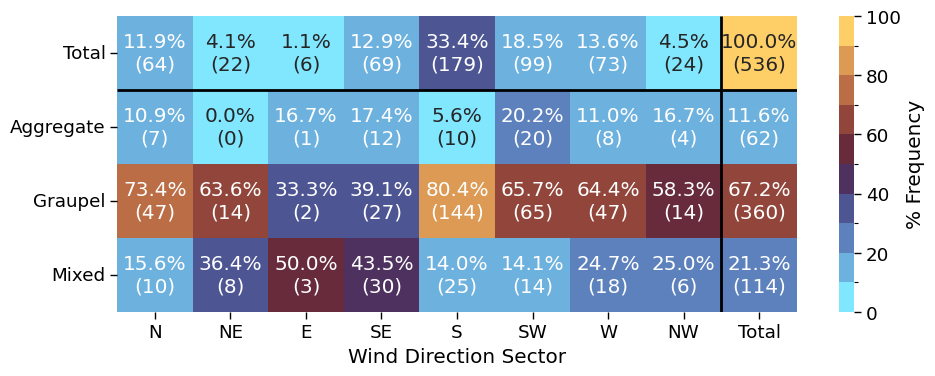

In [17]:
default_label = "% Frequency"
format = ".2f"
n_bins = 10
bounds = np.linspace(0, 100, n_bins +1)
cmap_base = cm.managua_r

cmaplist = [cmap_base(i/(n_bins -1)) for i in range(n_bins)]
custom_cmap = ListedColormap(cmaplist)
    
norm = BoundaryNorm(bounds, ncolors=custom_cmap.N)
# -----

# transpose for plotting
plot_data = pivot_percent.T
plot_counts = pivot_counts_with_total.T

# define y-axis order
desired_order = ['Total', 'aggregate', 'graupel', 'mixed', ]#'pristine']
plot_data = plot_data.loc[desired_order]

plot_counts = plot_counts.loc[desired_order]

# Capitalize y-axis labels
plot_data.index = [label.capitalize() for label in plot_data.index]
plot_counts.index = [label.capitalize() for label in plot_counts.index]

# Create annotation strings
annot_data = plot_data.round(1).astype(str) + "%\n(" + plot_counts.astype(int).astype(str) + ")"

# Plot 
plt.figure(figsize=(10, 4))


ax = sns.heatmap(plot_data, annot=annot_data, fmt="", cmap=custom_cmap, norm=norm, cbar_kws={'label': default_label})

# Labeling
ax.set_xlabel("Wind Direction Sector")
ax.set_ylabel("")
# visually separate Total row and column
ax.hlines(1, *ax.get_xlim(), colors='black', linewidth=2)
ax.vlines(8, *ax.get_ylim(), colors='black', linewidth=2)
plt.tight_layout()

# save image to png
plt.savefig(FIG_DIR + "fig04.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

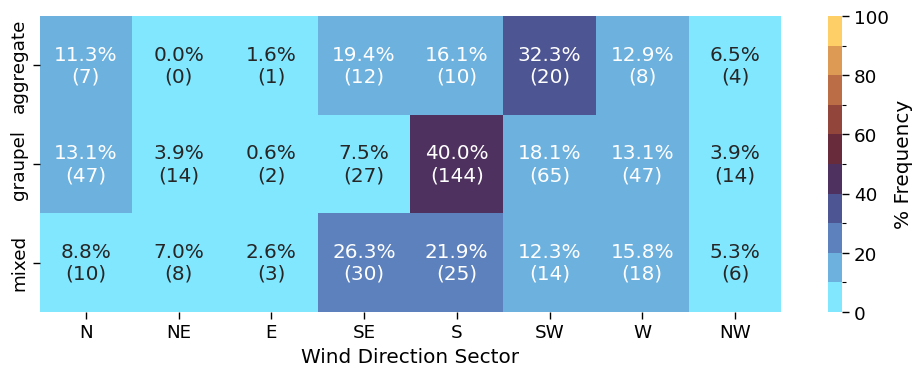

In [18]:
# Frequencies are normalized by wind sector, highlighting the relative distribution of snowflake habits for a given flow direction. 
#### Normalize by habit class instead of wind sector
# Given this habit, which wind direcitons did it occur?
pivot_plot_habit = pivot_60.div(pivot_60.sum(axis=0), axis=1)*100
# transpose for plotting consistency
pivot_plot_habit = pivot_plot_habit.T
# annotation for habit-normalized plot
annot_data_habit = (pivot_plot_habit.round(1).astype(str) +"%\n(" + 
                    pivot_60.T.astype(int).astype(str) + ")")
# Plot 
plt.figure(figsize=(10, 4))

ax = sns.heatmap(pivot_plot_habit, annot=annot_data_habit, fmt="", cmap=custom_cmap, norm=norm, cbar_kws={'label': default_label})

# Labeling
ax.set_xlabel("Wind Direction Sector")
ax.set_ylabel("")
plt.tight_layout()

# save image to png
# plt.savefig(FIG_DIR + "fig03b.png", format='png', bbox_inches='tight', transparent=True,dpi=300)
# Frequencies are normalized by snowflake habit, highlighting preferred wind directions for each habit class

## CFAD per particle type
use event-based data

In [19]:
H_ze = dict()
H_ze_prob = dict()

H_w = dict()
H_w_prob = dict()

H_ze_w = dict()
H_ze_w_prob = dict()

for sf_class, df_class in sf_class_dict.items():
    
    _ds_in_dt = fct.get_ds_in_precip_event(sf_class_dict[sf_class], ds_season)
    

    H_ze[sf_class], H_ze_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'Ze', 'range',np.arange(-10.5, 31, 1), np.arange(0.50, 31.50, 1.00))

    H_w[sf_class], H_w_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'W', 'range', np.arange(-4.05, 4.1, 0.1), np.arange(0.50, 31.50, 1.00))

    H_ze_w[sf_class], H_ze_w_prob[sf_class] = fct.probability_distribution(_ds_in_dt, 'W', 'Ze', np.arange(-4.05, 4.1, 0.1), np.arange(-10.5, 31, 1))



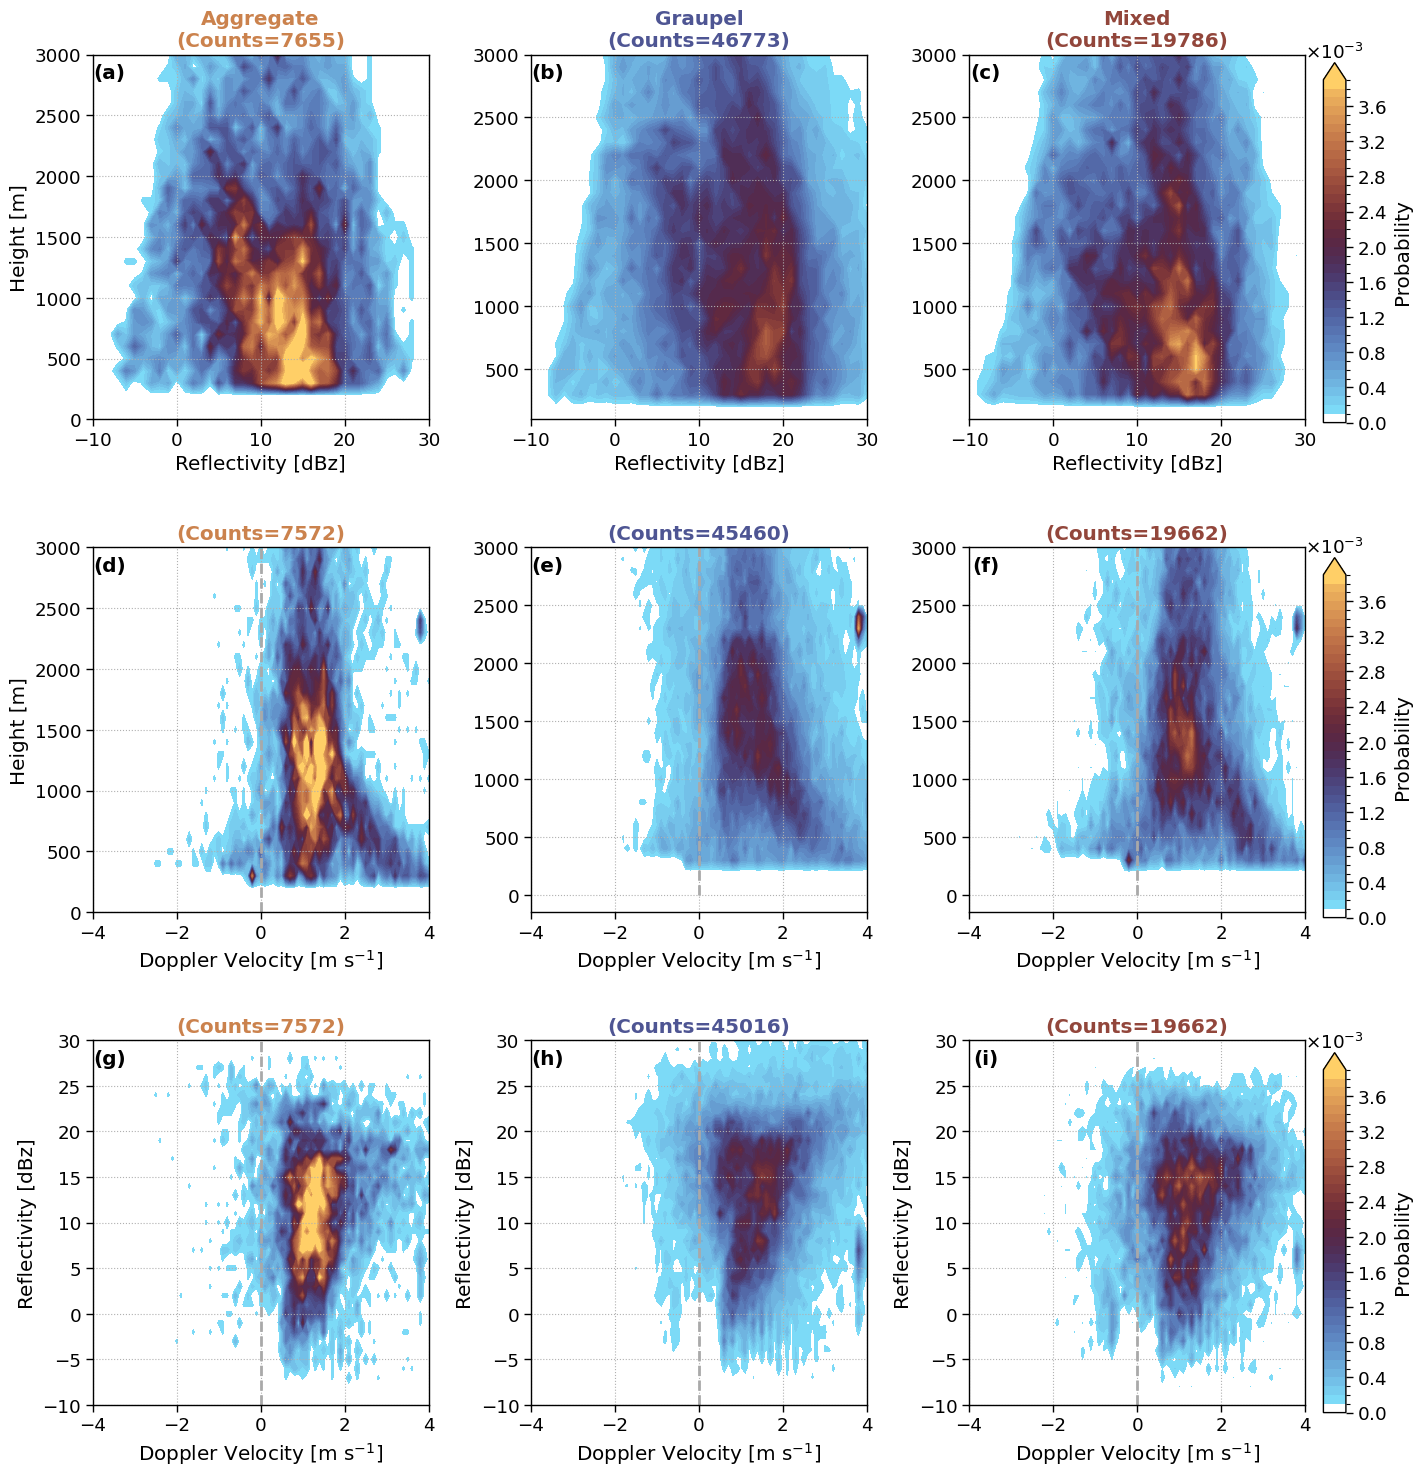

In [20]:
fct.plt_prob_agg_graupel_mixed(H_ze_prob, H_ze, H_w_prob, H_w, H_ze_w_prob, H_ze_w, category=['aggregate_60', 'graupel_60', 'mixed_60'])
# save image to png
# plt.savefig(FIG_DIR + "figA1.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

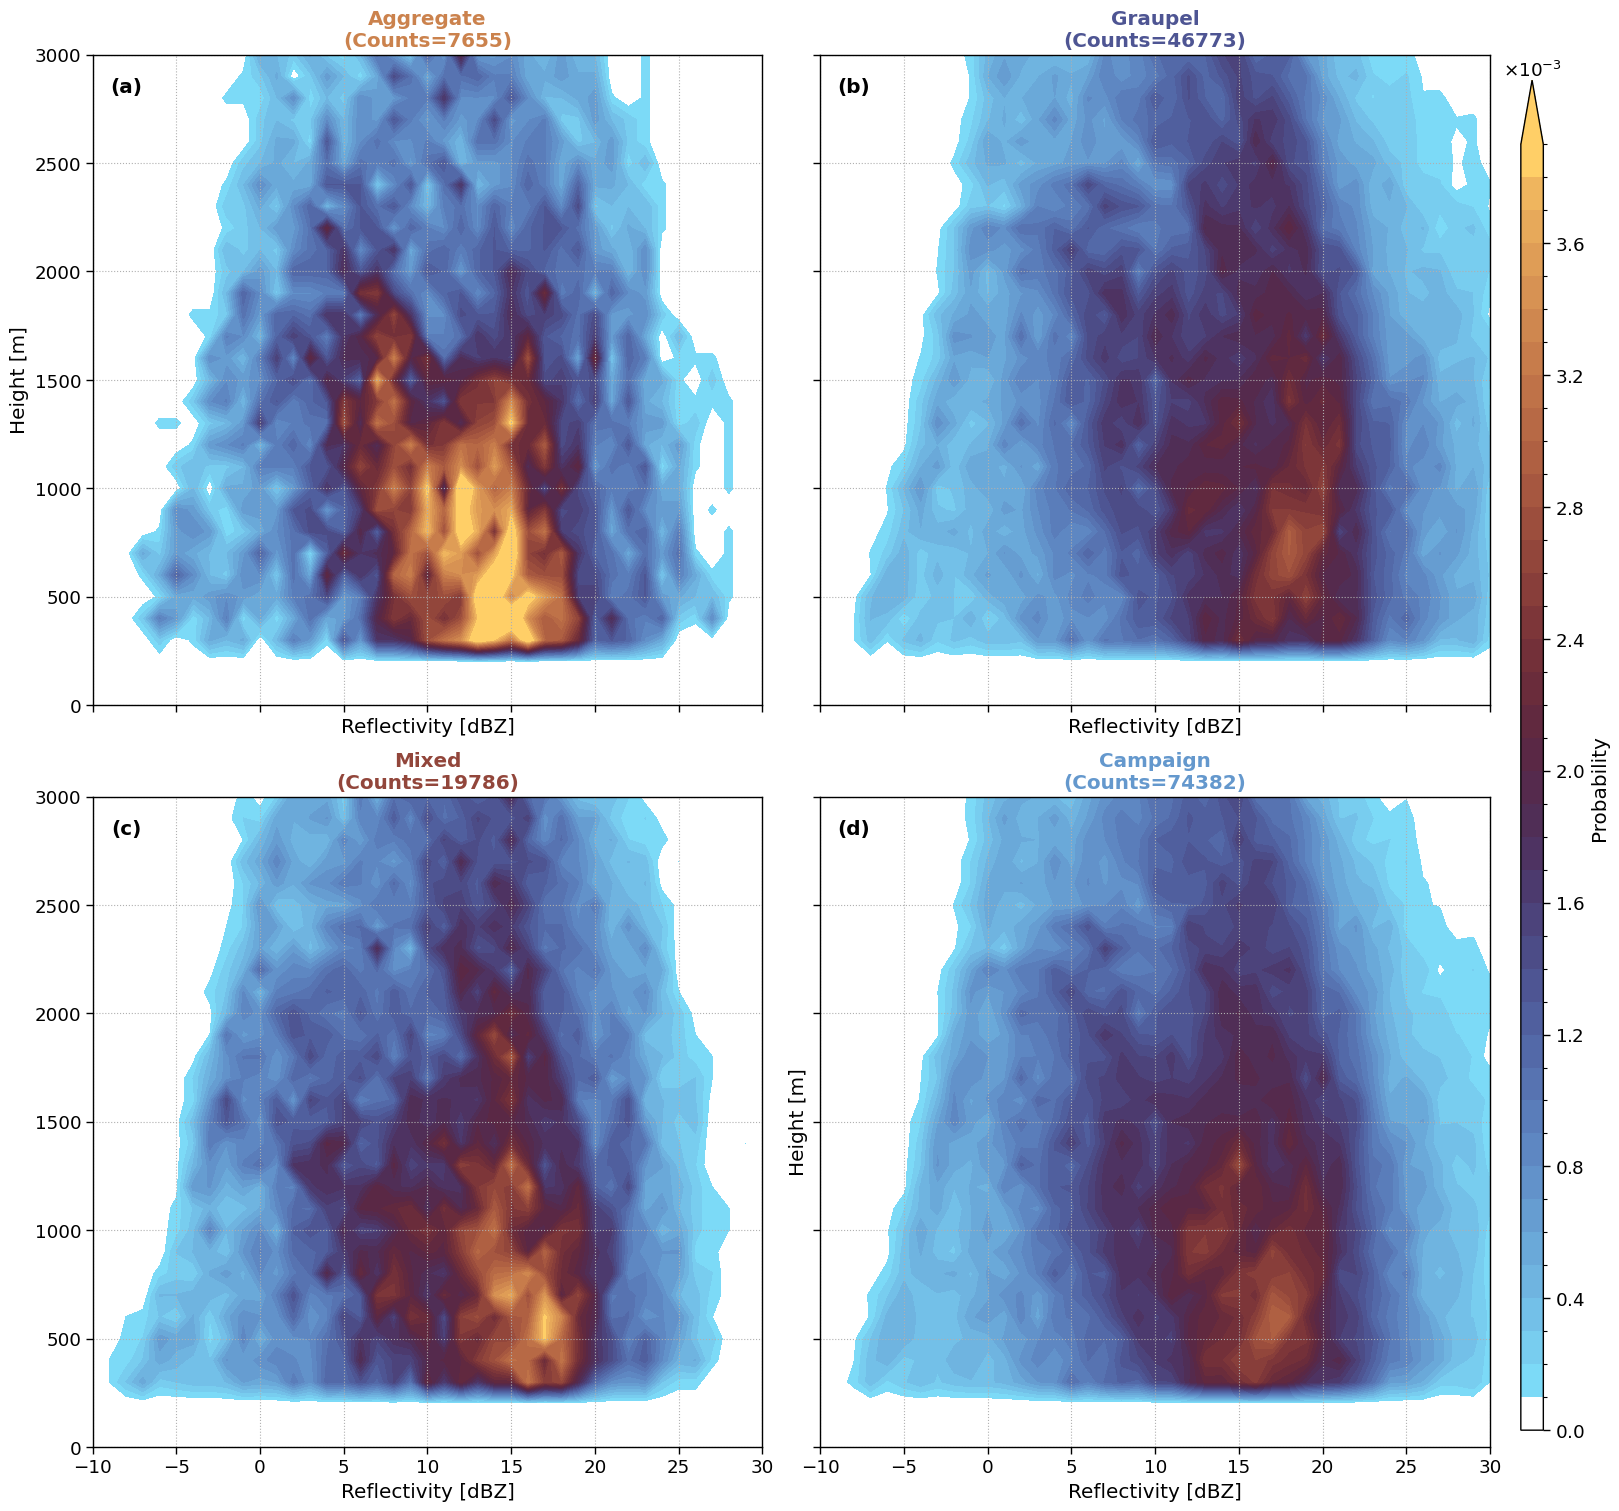

In [21]:
fct.plt_CFAD_agg_graupel_mixed_all(H_ze_prob, H_ze, np.arange(-10, 31,1), ['aggregate_60', 'graupel_60', 'mixed_60', 'campaign'], xlabel="Reflectivity [dBZ]")
# plt.savefig(FIG_DIR + "fig05.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

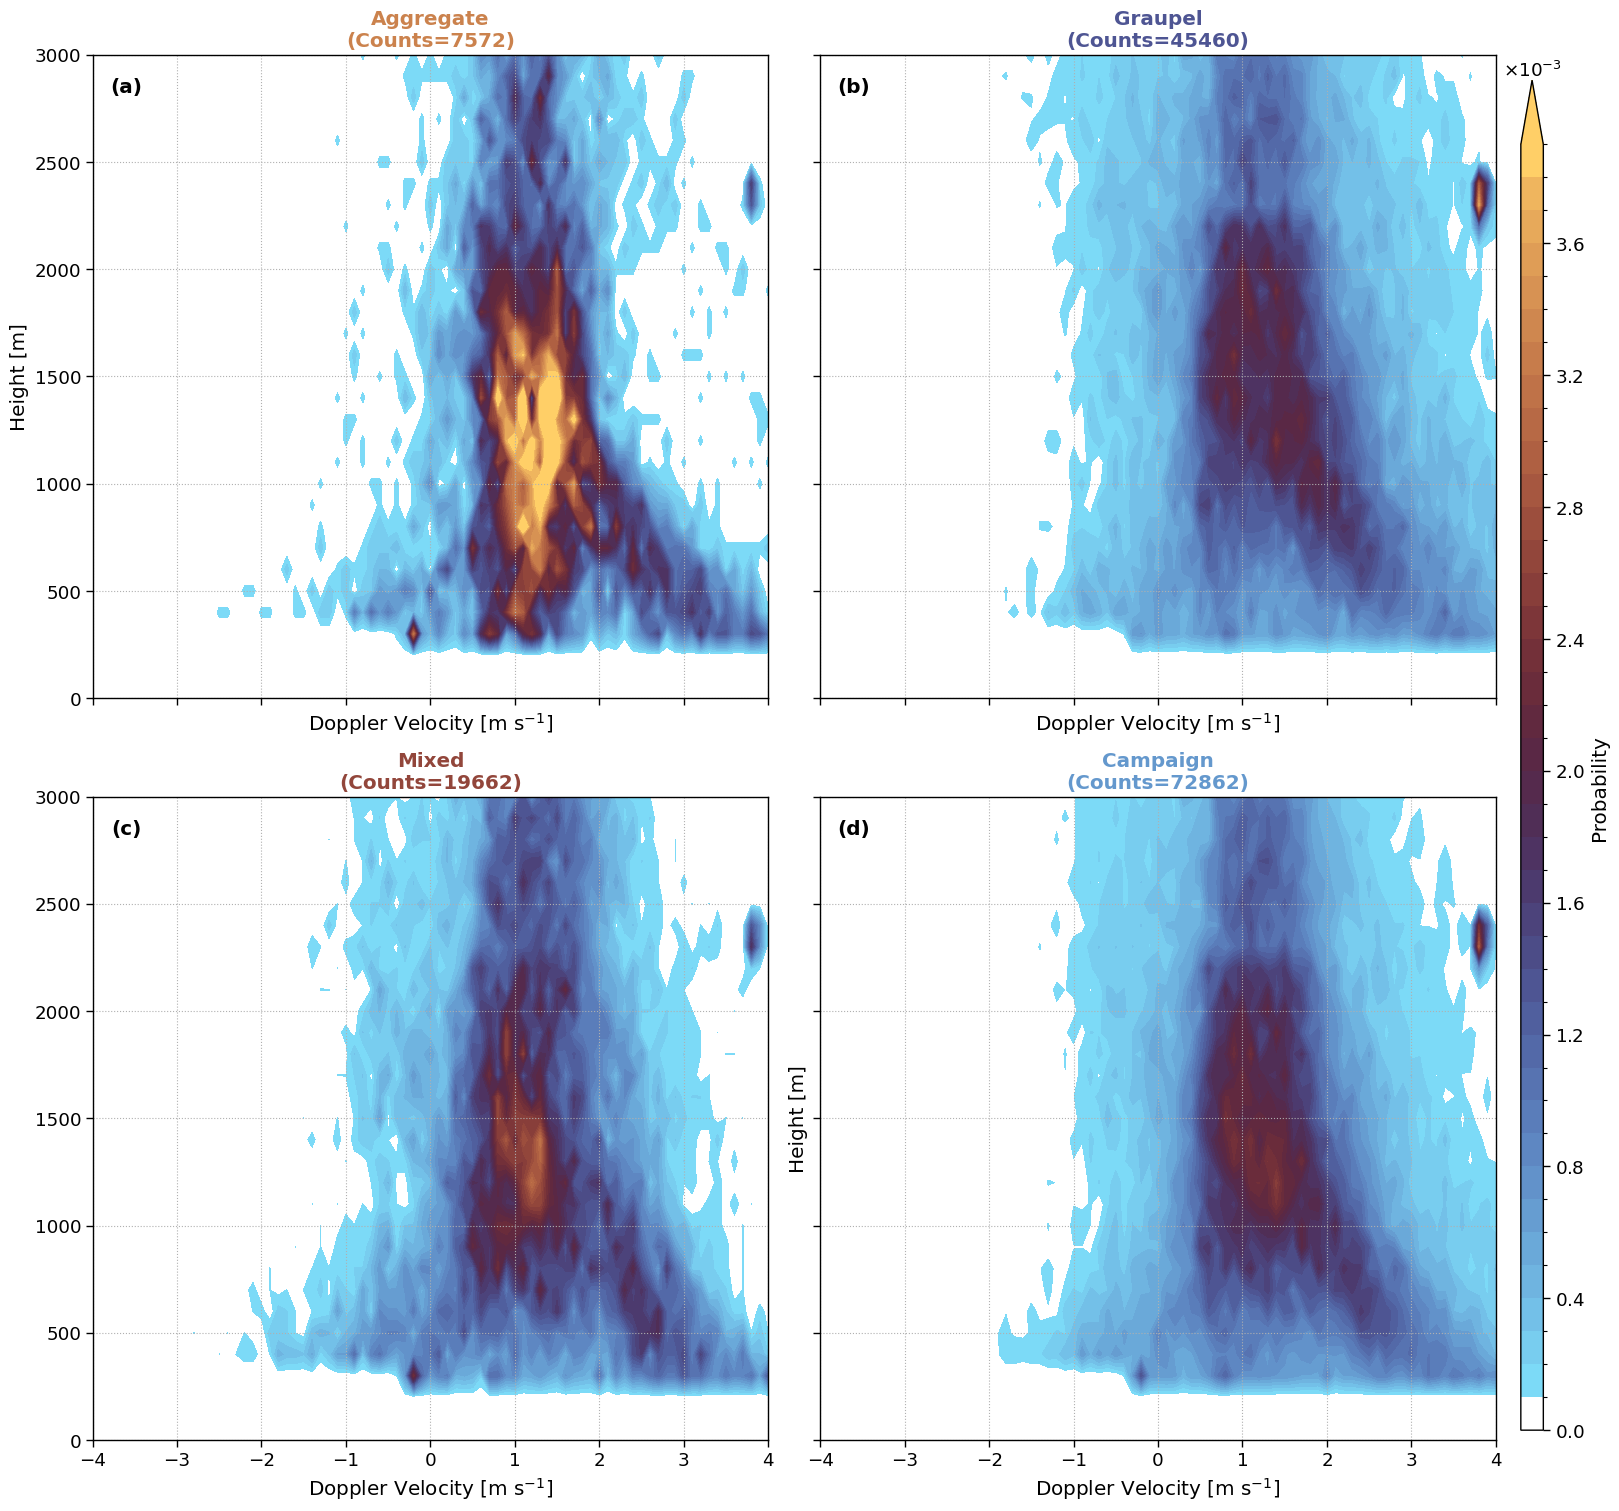

In [22]:
fct.plt_CFAD_agg_graupel_mixed_all(H_w_prob, H_w, np.arange(-4, 4.1, 0.1), ['aggregate_60', 'graupel_60', 'mixed_60', 'campaign'], xlabel="Doppler Velocity [m s$^{{-1}}$]")
# plt.savefig(FIG_DIR + "figA1.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

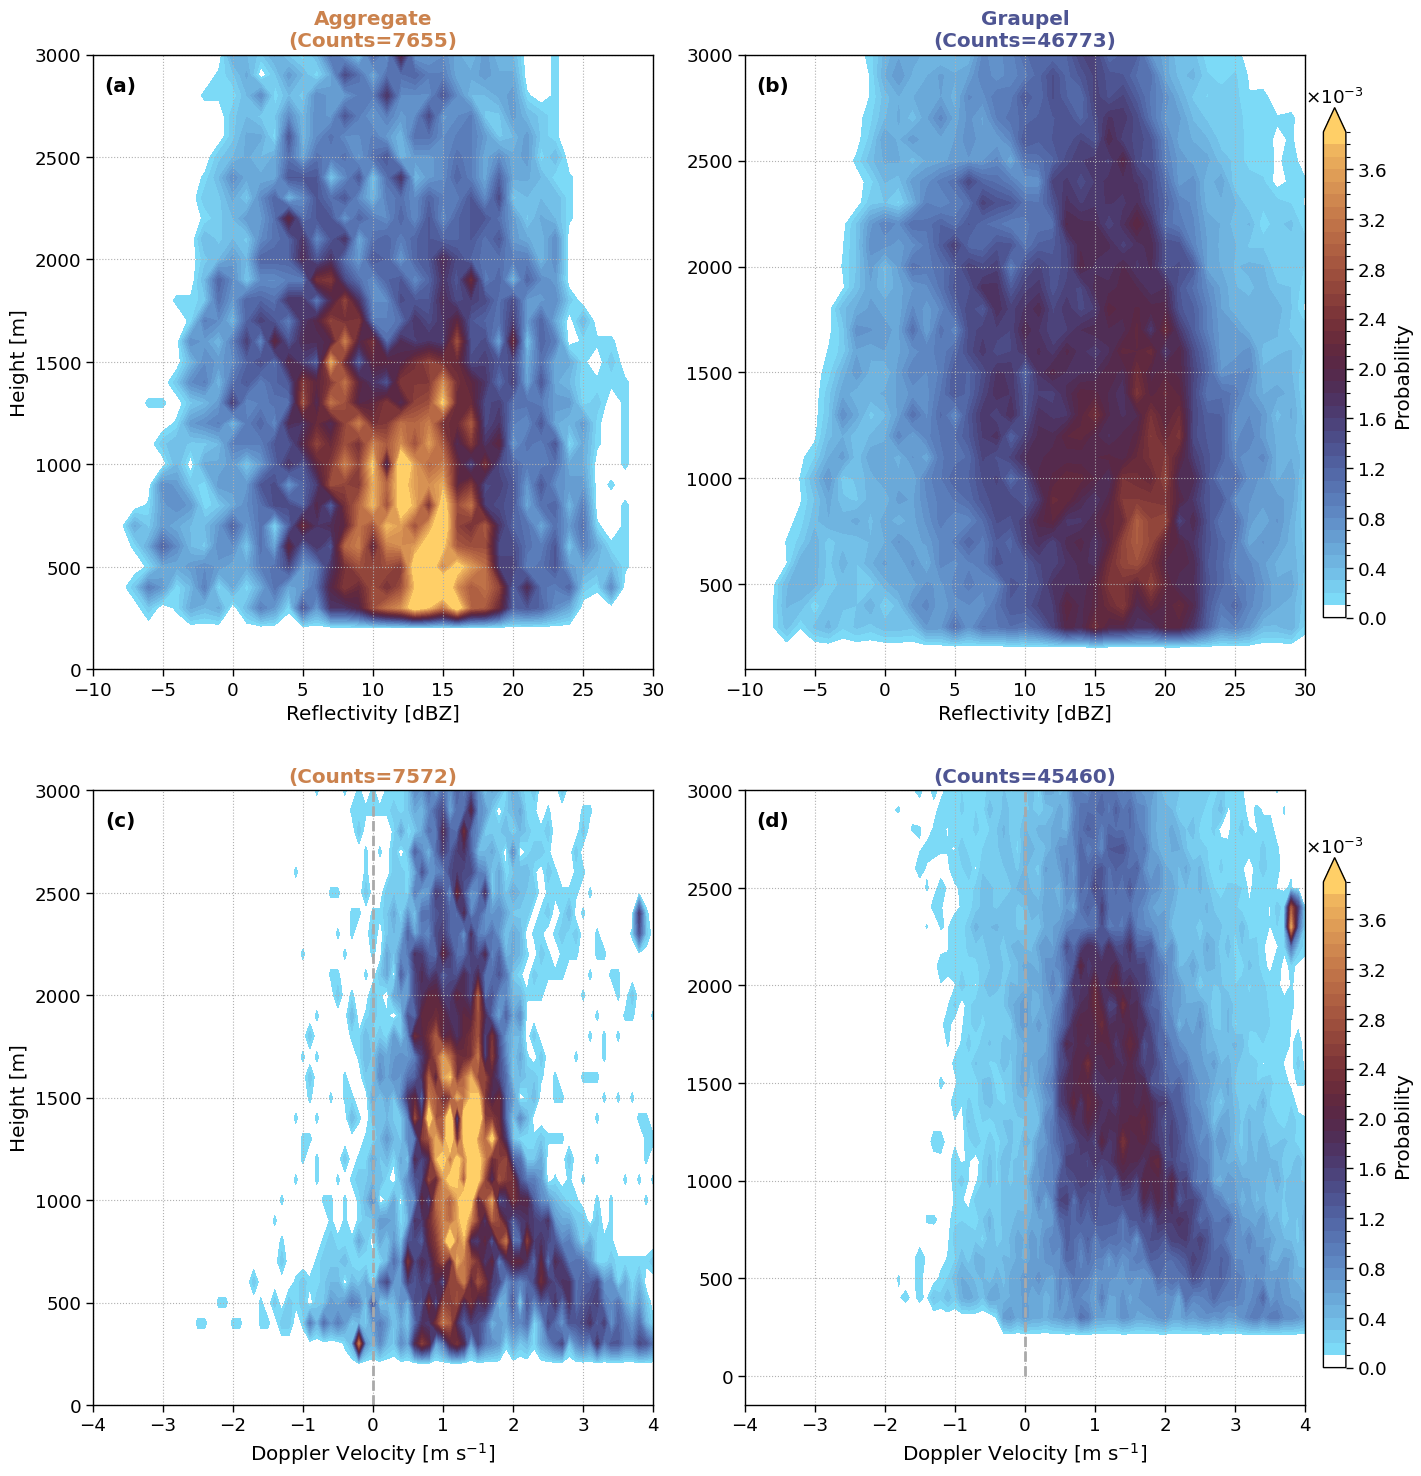

In [23]:
fct.plt_prob_agg_graupel_Ze_W(H_ze_prob, H_ze, H_w_prob, H_w, ['aggregate_60', 'graupel_60', ])
plt.savefig(FIG_DIR + "fig03.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

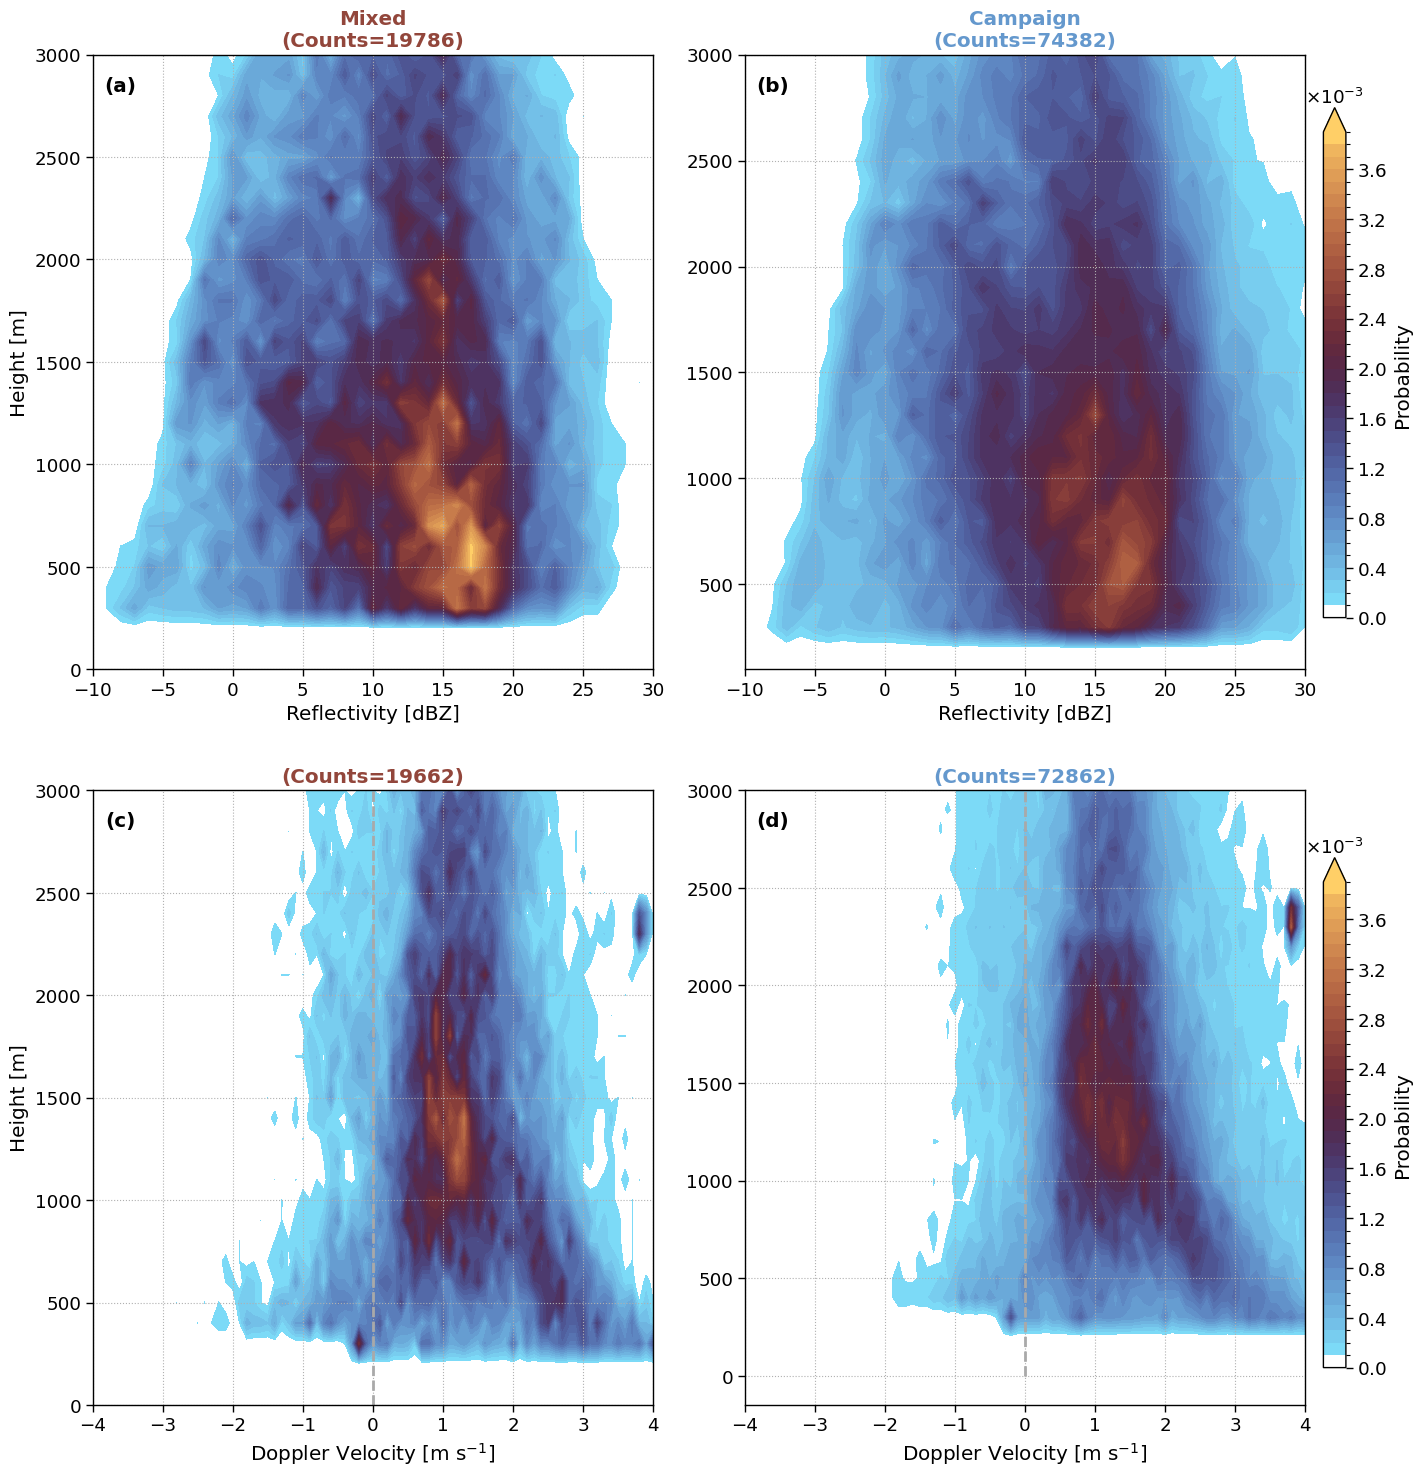

In [24]:
fct.plt_prob_agg_graupel_Ze_W(H_ze_prob, H_ze, H_w_prob, H_w, ['mixed_60', 'campaign'])
plt.savefig(FIG_DIR + "figA2.png", format='png', bbox_inches='tight', transparent=True,dpi=300)

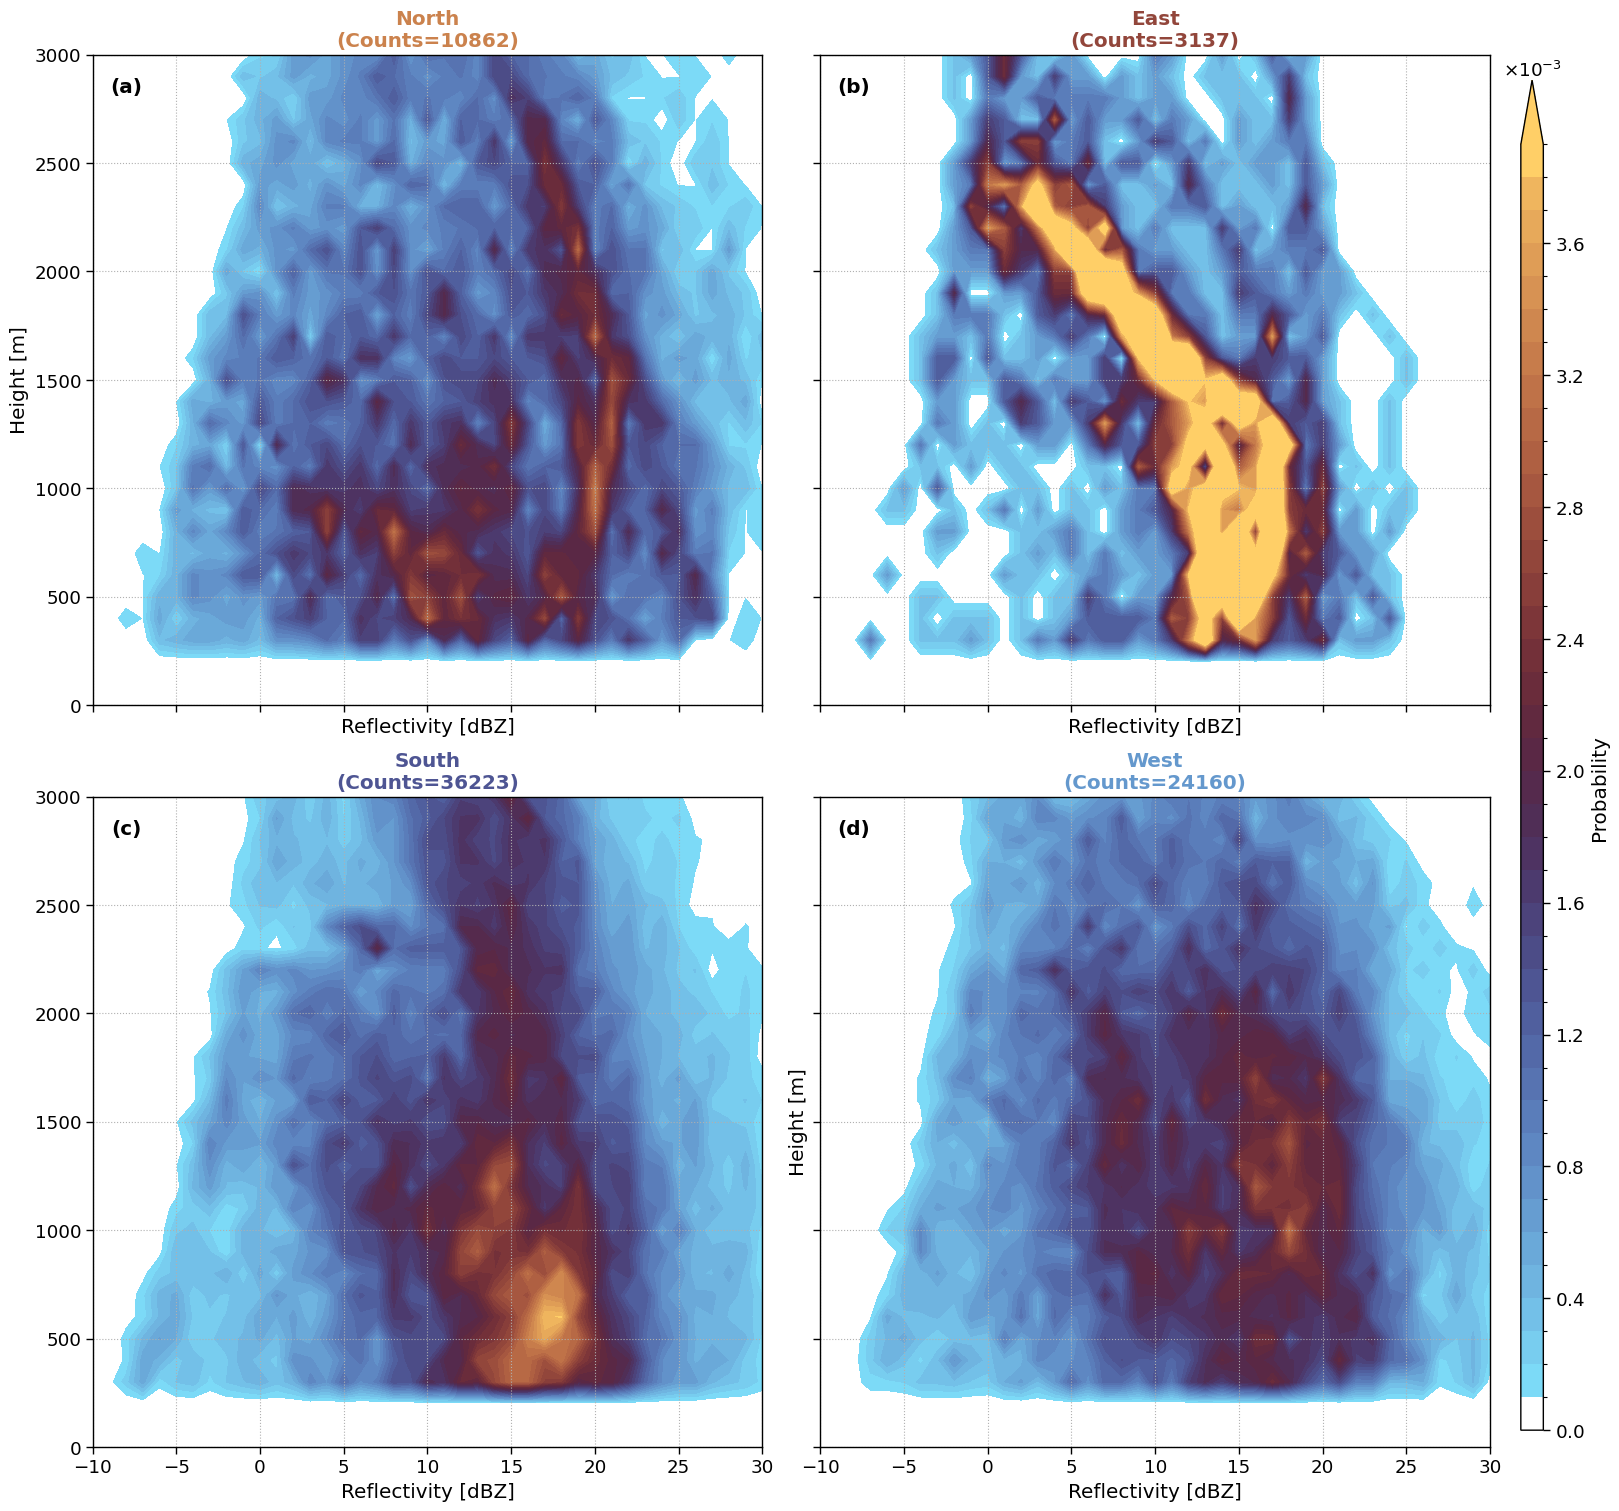

In [25]:
fct.plt_CFAD_agg_graupel_mixed_all(H_ze_prob, H_ze, np.arange(-10, 31,1), ['North', 'East', 'South', 'West'], xlabel="Reflectivity [dBZ]")

## Dominant snowfall class name by hour

In [26]:
agg_count = sf_class_dict['aggregate_60']['snowflake_class_name_60'].groupby([sf_class_dict['aggregate_60'].index.date, sf_class_dict['aggregate_60'].index.hour]).count().rename('aggregate_count')

grau_count = sf_class_dict['graupel_60']['snowflake_class_name_60'].groupby([sf_class_dict['graupel_60'].index.date, sf_class_dict['graupel_60'].index.hour]).count().rename('graupel_count')

mix_count = sf_class_dict['mixed_60']['snowflake_class_name_60'].groupby([sf_class_dict['mixed_60'].index.date, sf_class_dict['mixed_60'].index.hour]).count().rename('mixed_count')

pris_count = sf_class_dict['pristine_60']['snowflake_class_name_60'].groupby([sf_class_dict['pristine_60'].index.date, sf_class_dict['pristine_60'].index.hour]).count().rename('pristine_count')

# camp_count = sf_class_dict['campaign']['snowflake_class_name_60'].groupby([sf_class_dict['campaign'].index.date, sf_class_dict['campaign'].index.hour]).count().rename('pristine_count')

sf_class_count = pd.concat([agg_count, grau_count, mix_count, pris_count], axis=1)
pd.concat([sf_class_count.max(axis=0), sf_class_count.idxmax(axis=0)], axis=1)

KeyError: 'pristine_60'

In [ ]:
sf_class_count.nlargest(3,'aggregate_count')

aggregate_count  graupel_count  mixed_count  pristine_count
           time                                                             
2023-02-23 9                13.0            NaN          4.0             NaN
           8                 8.0            1.0          5.0             NaN
           7                 7.0            NaN          2.0             NaN

In [ ]:
sf_class_count.nlargest(3,'graupel_count')

aggregate_count  graupel_count  mixed_count  pristine_count
           time                                                             
2023-03-08 17                NaN           21.0          2.0             NaN
           19                NaN           19.0          1.0             NaN
2023-03-04 17                1.0           14.0          6.0             NaN

In [ ]:
### Aggregate case: 2023-02-23 9:00 to 2023-02-23 9:59
sf_class_dict['campaign'].loc["2023-02-23 7:00:00": "2023-02-23 08:00:00"]

### Graupel case: 2023-03-08 17:00 to 2023-03-08 17:59
sf_class_dict['campaign'].loc["2023-03-08 17:00:00": "2023-03-08 18:00:00"]

# This plot is done in /Python/oesr_adjust/retrieval_analysis/work/MASCDB/plot_triplet.ipynb



,Geonor,air_temperature,wind_direction,wind_speed,snowflake_class_name_60,snowflake_class_name_70,snowflake_class_name_80,rate_mm_h,start_time,delta_h,...,S_9_7.3_400_mm_h,S_9_7.4_400_mm_h,S_9_7.5_400_mm_h,S_9_7.6_400_mm_h,S_9_7.7_400_mm_h,S_9_7.8_400_mm_h,S_9_7.9_400_mm_h,S_9_8.0_400_mm_h,wind_direction_sector_4,wind_direction_sector_8
time,,,,,,,,,,,,,,,,,,,,,
2023-03-08 17:01:00,0.2512,NaN,170.000000,7.100000,graupel,graupel,mixed,3.014400,2023-03-08 16:56:00,0.083333,...,1.287480,1.283082,1.278816,1.274676,1.270656,1.266752,1.262959,1.259271,S,SE
2023-03-08 17:04:00,0.1260,NaN,170.000000,6.700000,graupel,graupel,mixed,2.520000,2023-03-08 17:01:00,0.050000,...,1.367775,1.361996,1.356394,1.350962,1.345692,1.340577,1.335610,1.330785,S,SE
2023-03-08 17:06:00,0.1257,NaN,170.000000,6.700000,graupel,mixed,mixed,3.771000,2023-03-08 17:04:00,0.033333,...,1.370655,1.364825,1.359174,1.353694,1.348378,1.343218,1.338208,1.333342,S,SE
2023-03-08 17:08:00,0.1261,NaN,170.000000,6.700000,graupel,mixed,mixed,3.783000,2023-03-08 17:06:00,0.033333,...,1.463156,1.455644,1.448369,1.441321,1.434489,1.427864,1.421436,1.415196,S,SE
2023-03-08 17:11:00,0.1256,NaN,170.000000,6.700000,graupel,graupel,mixed,2.512000,2023-03-08 17:08:00,0.050000,...,1.441084,1.433977,1.427093,1.420423,1.413956,1.407684,1.401597,1.395688,S,SE
2023-03-08 17:12:00,0.1257,NaN,170.000000,6.700000,mixed,mixed,mixed,7.542000,2023-03-08 17:11:00,0.016667,...,1.426439,1.419609,1.412992,1.406579,1.400361,1.394329,1.388474,1.382789,S,SE
2023-03-08 17:13:00,0.2518,NaN,170.000000,6.700000,graupel,graupel,mixed,15.108000,2023-03-08 17:12:00,0.016667,...,1.360128,1.354486,1.349017,1.343714,1.338568,1.333573,1.328723,1.324011,S,SE
2023-03-08 17:16:00,0.2520,NaN,170.000000,6.700000,graupel,mixed,mixed,5.040000,2023-03-08 17:13:00,0.050000,...,1.316362,1.311480,1.306746,1.302154,1.297696,1.293367,1.289161,1.285074,S,SE
2023-03-08 17:18:00,0.1257,NaN,170.000000,6.700000,mixed,mixed,mixed,3.771000,2023-03-08 17:16:00,0.033333,...,1.318349,1.313434,1.308667,1.304043,1.299554,1.295195,1.290961,1.286846,S,SE


## RMSE (a,b) ensemble space
This plot is done in /Python/oesr_adjust/retrieval_analysis/work/combined_obs/07_ensemble_approach.ipynb

## Seasonal/campaign accumulation
This plot is done in /Python/oesr_adjust/retrieval_analysis/work/combined_obs/07_ensemble_approach.ipynb

#### Plot the distribution of 1-minute reflectivity values at 400 m (in dBZ) over the full campaign

x-axis --> reflectivity bins (dBZ)
y-axis --> number of minutes falling in each bin

==> each count = one minute of radar data

**Answers: Which Z values dominate my retrievals?**

In [ ]:
# # clea data
# Z = ds_23['Ze_400m'].values
# # keep only finit values
# Z = Z[np.isfinite(Z)]
# # remove very low reflectivties
# Z = Z[Z > -10.]


# fig, ax = plt.subplots(1,1, figsize=(7,5))
# ax.hist(Z, bins=np.arange(-10,35,1), # 1 dB bins 
#         color='steelblue',
#         edgecolor='black',
#         alpha=0.75)

# # for z in [-5, 0, 5, 10]: # sensitivity of retrieval
# #     ax.axvline(z, color='k', ls='--', alpha=0.4)

# q = np.percentile(Z, [10, 25, 50, 75, 90])
# for z in q:
#         ax.axvline(z, color='k', ls='--', alpha=0.4)

# ax.text(q[2], ax.get_ylim()[1]*0.9, 'median', rotation=90)


# ax.text(0.02, 0.95,
#         f'N = {len(Z):,} minutes',
#         transform=ax.transAxes,
#         va='top')


# ax.set_xlabel('Reflectivity at 400 m [dBZ]')
# ax.set_ylabel('Number of minutes')
# ax.grid(True, ls=':')

#### Where snowfall contribution peaks

In [ ]:
# # weight by snowfall rate
# weights = df['rate_mm_h'].values
# Zf = df['Ze_400m'].values

# bins = np.arange(-10, 35, 1)
# bin_centers = 0.5 * (bins[:-1] + bins[1:])

# S_sum, _ = np.histogram(Zf, bins=bins, weights=weights)

# ax.plot(bin_centers, S_sum / S_sum.sum(), color='red')
# ax.set_ylabel('Fraction of total snowfall')


In [ ]:
# ds_23['W'] = ds_23['W'].where(ds_23['W'] <= 7., other=np.nan)
# ds_23['W'] = ds_23['W'].where(ds_23['W'] > -7., other=np.nan)

In [ ]:
# df = dict()
# df_nearest = dict()
# df_no_sf_class = dict()
# vars_to_keep = ['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'snowflake_class_name', 'rate_mm_h', 
#                 'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400',
#                 'Matrosov_a_400_mm_h', 'Bracci_a_400_mm_h', 'Nakai_a_400_mm_h', 'Nakai_g_400_mm_h', 'Pu_g_400_mm_h', 'start_time', 'Ze_400m']

# open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_event_dt_offset_{site}_{year}.nc'))))
# df['event_offset'] = open_ds[vars_to_keep].to_dataframe()

# open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_nearest_class_precip_event_dt_offset_{site}_{year}.nc'))))
# df_nearest['event_offset'] = open_ds_nearest[vars_to_keep].to_dataframe()
# open_ds_nearest.close()

# open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_event_{site}_{year}.nc"))))
# df_no_sf_class['event_offset'] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'rate_mm_h', 
#                                                      'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()

# for dt in ['1min', '5min', '10min', '30min', '60min']:
#     open_ds = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f'Z_S_2Tm_WD_WS_class_precip_{dt}_dt_offset_{site}_{year}.nc'))))
#     df[dt] = open_ds[vars_to_keep].to_dataframe()


#     open_ds_nearest = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_nearest_class_precip_{dt}_dt_offset_{site}_{year}.nc"))))
#     df_nearest[dt] = open_ds_nearest[vars_to_keep].to_dataframe()
#     open_ds_nearest.close()

#     open_ds_no_sf_class = xr.open_mfdataset(sorted(glob(os.path.join(OUTPUT_DATA_DIR, 'ANX_obs', f"Z_S_2Tm_WD_WS_precip_{dt}_dt_{site}_{year}.nc"))))
#     df_no_sf_class[dt] = open_ds_no_sf_class[['Geonor', 'air_temperature', 'wind_direction', 'wind_speed', 'rate_mm_h', 
#                                              'Matrosov_a_400', 'Bracci_a_400', 'Nakai_a_400', 'Nakai_g_400', 'Pu_g_400']].to_dataframe()
    

In [ ]:
# # Colorbar layout parameters
# cbar_left = 0.95
# cbar_width = 0.015
# cbar_height = 0.15
# cbar_top = 0.75
# cbar_step = 0.1075  # vertical space between cbar axes

# # Reflectivity'
# # Define your radar-style reflectivity levels (can match the image closely)
# bounds  = np.array([0, 3.5, 7, 10.5, 14, 17.5, 21, 24.5, 28])
# bounds = np.linspace(0, 28, 9)
# bounds = np.linspace(0, 28, 17)
# norm= fct.BoundaryNorm(boundaries=bounds, ncolors=256)  # hawaii_r has 256 levels
# # Use Crameri colormap (hawaii_r)
# cmap= cm.hawaii_r
# cmap = cm.managua_r

### Graupel case: 2023-03-08 12:00 to 2023-03-09 06:00

In [ ]:
# date = '20230308'

# day_start = pd.Timestamp(f"{date} 17:00:00")
# # day_end = day_start + pd.Timedelta(hours=23, minutes=59)
# day_end = day_start + pd.Timedelta(hours=3)
# xmin = day_start + pd.Timedelta(hours=0)
# xmax = day_start + pd.Timedelta(hours=3)

# ds_day = ds_23.sel(time=slice(day_start, day_end))
# dt = '1min'
# df_day = df[dt].loc[slice(xmin, xmax)]

In [ ]:
# time_vals = fct.date2num(ds_day['time'].values)

# # Define the region to highlight
# x_start = xmin - pd.Timedelta(minutes=5)
# x_end = xmax + pd.Timedelta(minutes=5)
# y_start = 0.5 # slightly below the min y-value 
# y_end = 30.5
# x_width = x_end - x_start
# y_height = y_end - y_start


# fig, axsm = plt.subplots(4, 1, figsize=(8.27, 7.014/3*4), )#sharex=True, )
# axs = axsm.flatten()

# # a) 
# fct.plot_pcolormesh_with_cbar(ax=axs[0], fig=fig, data=ds_day['Ze'].transpose('range','time'), x=time_vals, y=ds_day['range'], cmap=cmap, norm=norm, cbar_bounds=bounds[::2], cbar_label=f"Reflectivity [{ds_day['Ze'].attrs['units']}]", cbar_pos=[cbar_left, cbar_top -0 *cbar_step, cbar_width, cbar_height])
# axs[0].hlines(4., ds_day.time.values[0], ds_day.time.values[-1], colors='k', linestyles='-.', label='400m')
# axs[0].legend(loc='upper right')
# axs[0].set_xlim([day_start, day_end])


# # create a rectangle path
# # rect = Rectangle((x_start, y_start), x_width, y_height, linewidth=2, edgecolor='k', linestyle='-', fill=False, )
# # axs[0].add_patch(rect)

# fct.format_range_axis(axs[0], ds_day)
# # -----------

# # b)
# counts = []
# for y_pos, (name, level) in enumerate(particle_classes, 1) :
    
#     data = (df_day['snowflake_class_name'].where(df_day['snowflake_class_name'] == name)).dropna()
#     counts.append(len(data))

#     axs[1].plot(fct.date2num(data.index), 
#                 np.full(len(data.index), level),
#                 marker=markers[y_pos - 1], linestyle='None',
#                 color=fct.custom_colors[name], markersize=12, label=name, alpha=0.7)
    

# axs[1].set_yticks(range(1,5))
# axs[1].set_yticklabels([f"{name} ({cnt})" for (name, _), cnt in zip(particle_classes, counts)])
# # -----------

# # c)
# dt = "event_offset"
# for var, var_c in colors.items():
#     # df_sec = df[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
#     df_sec = df_nearest[dt].loc[slice(xmin, xmax + pd.Timedelta(hours=1))]
#     precip = df_sec[var].resample('1H', closed='left', label='left').sum()
#     if var == 'Geonor':
#         axs[2].bar(precip.index+pd.Timedelta(minutes=30), precip, width=np.timedelta64(60,'m'), align='center', color=var_c[0], edgecolor='k', label=var_c[1])
#     else: 
#         axs[2].scatter(precip.index+pd.Timedelta(minutes=30), precip, marker=var_c[3], color=var_c[0], s=150, edgecolor=var_c[0])
# axs[2].set_ylabel("[mm  h$^{-1}$]")
# axs[2].set_ylim([0, 4])
# # axs[2].set_xlim([x_start, x_end])


# # -----------

# # d)
# for var, var_c in colors.items():
#     # df_sec = df[dt].loc[slice(xmin, xmax)]
#     # precip = df_day[var].fillna(0).cumsum()
#     df_sec = df_nearest[dt].loc[slice(xmin, xmax)]
#     precip = df_sec[var].fillna(0).cumsum()
#     if var == 'Geonor':
#         linewidth = 3
#     else:
#         linewidth = 2
#     axs[3].plot(precip.index, precip, color=var_c[0], label=var_c[1], linestyle=var_c[2], linewidth=linewidth)
# axs[3].set_ylabel("[mm]")
# axs[3].set_ylim([0, 10])
# # axs[3].set_xlim([x_start, x_end])
# # -----------

# # pairing: either (marker,line) or (line,marker) depending on visual preference
# legend_items = [
#     geonor_line,
#     (matro_mark, matro_line),
#     (bracci_mark, bracci_line),
#     (nakaiA_mark, nakaiA_line),
#     (nakaiG_mark, nakaiG_line), 
#     (Pu_mark, Pu_line)
# ]
# bb = (fig.subplotpars.left -0.1, fig.subplotpars.bottom-0.15, 
# fig.subplotpars.right-fig.subplotpars.left + 0.2,.1)

# axs[3].legend(
#     handles = legend_items,
#     labels  = legend_labels,
#     handler_map={tuple: HandlerTuple(ndivide=None)},
#     bbox_to_anchor=bb, mode="expand", loc="lower left",
#     ncol=2, borderaxespad=0., bbox_transform=fig.transFigure
# )



# date_form = DateFormatter("%H:%M")
# for (i, ax), title in zip(enumerate(axs), ["MRR Reflectivity", "Snowflake Class (MASCDB)", "Observations vs. Z-S Relationships from Literature", "Cumulative Bias"]):
#     ax.set(xlabel= "", title=title)
#     ax.text(0.045, 0.9, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = ax.transAxes)
#     ax.xaxis.grid(ls=':')
#     if i == 1 or i == 3: 
#         ax.yaxis.grid(ls=':')
#     if i in [1, 2, 3]:
#         ax.set_xlim([x_start, x_end])

#     ax.tick_params(axis='x', labelrotation=0)
#     plt.setp(ax.get_xticklabels(), horizontalalignment="center")
#     ax.xaxis_date()
#     ax.xaxis.set_major_formatter(date_form)
# axs[-1].set(xlabel="Time [UTC]")
# axs[-1].yaxis.grid(ls=':')

# # fig.suptitle(f"{si te.split('.')[0]} ({ds_day.time.dt.date[0].values} — {ds_day.time.dt.date[-1].values})", fontweight="bold")
# fig.subplots_adjust(top=0.91, hspace=0.5, )

# # save image to png
# plt.savefig(FIG_DIR + f'fig06.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)

### Geonor vs. Literature precipitation scatter
use event-based data

In [ ]:
# fct.plt_precip_scatter_literature(sf_class_dict[dt], title="")
# save image to png
# plt.savefig(FIG_DIR + f"precip_vs_literature_precip_1min_{site}_20230219_20230313.png", format='png', bbox_inches='tight', transparent=True,dpi=300)


### Cumulation season
Use the event-based data and the "nearest" crystal class data

In [ ]:
# # Combine where MASC observes aggregate --> apply Z-S for aggregates, 
# # where MASC observes graupel --> apply Z-S for graupel 
# # For the combined Z-S relationship, use the "nearest" observe snowflake type (done in different notebook).
# # For the "mixed" category, do the calculation twice, once where I assume mixed=graupel and another time where mixed=aggregate

# # mixed = aggregate
# mixed_aggregate=pd.DataFrame()
# mixed_aggregate['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
# mixed_aggregate['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
# mixed_aggregate['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
# mixed_aggregate['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

# mixed_aggregate['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Matrosov_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
# mixed_aggregate['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Bracci_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
# mixed_aggregate['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_a_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

# # mixed = graupel
# mixed_graupel=pd.DataFrame()
# mixed_graupel['Geonor_aggregate_graupel_only'] = pd.concat([aggregate_nearest[dt]['Geonor'], mixed_nearest[dt]['Geonor'], graupel_nearest[dt]['Geonor']]).sort_index()
# mixed_graupel['Matrosov_Nakai'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
# mixed_graupel['Bracci_Nakai'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()
# mixed_graupel['Nakai_Nakai'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Nakai_g_400'], graupel_nearest[dt]['Nakai_g_400']]).sort_index()

# mixed_graupel['Matrosov_Pu'] = pd.concat([aggregate_nearest[dt]['Matrosov_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
# mixed_graupel['Bracci_Pu'] = pd.concat([aggregate_nearest[dt]['Bracci_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()
# mixed_graupel['Nakai_Pu'] = pd.concat([aggregate_nearest[dt]['Nakai_a_400'], mixed_nearest[dt]['Pu_g_400'], graupel_nearest[dt]['Pu_g_400']]).sort_index()

In [ ]:
# fig, axd = plt.subplot_mosaic([['first', 'first'],
#                                ['second', 'second'],
#                                ['left', 'right'],
#                                ],
#                               constrained_layout=True, figsize=(20,15), )#sharex=True)

# # a)
# for var, var_c in colors.items():
#     if var == 'Geonor':
#         linewidth = 5
#     else: 
#         linewidth = 3
#     # precip2 = ds_season[var].cumsum()
#     # axd['first'].plot(precip2.time.values, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
#     precip = df_season_no_sf_class[var].cumsum()
#     precip = precip.fillna(method='ffill')
#     axd['first'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
# axd['first'].set_ylim([0, 110])
# # -----------

# # b)
# for var, var_c in colors.items():
#     if var == 'Geonor':
#         linewidth = 5
#     else: 
#         linewidth = 3
#     precip = df_season[var].cumsum(skipna=True)
#     precip = precip.fillna(method='ffill')
#     axd['second'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2])
#     # for t in no_masc_times:
#     #     axd['left'].axvline(t, color="red", alpha=0.15, linewidth=6)
#     # Shade gaps

# axd['second'].set_ylim([0, 110])
# # -----------

# # c) and d)
# for var, var_c in colors2.items():
#     if var == 'Geonor_aggregate_graupel_only':
#         linewidth = 5
#     else:
#         linewidth = 3
#     precip = mixed_aggregate[var].cumsum(skipna=True)
#     precip = precip.fillna(method='ffill')
#     axd['left'].plot(precip.index, precip, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)
    

#     precip2 = mixed_graupel[var].cumsum(skipna=True)
#     precip2 = precip2.fillna(method='ffill')
#     axd['right'].plot(precip2.index, precip2, color=var_c[0], label= var_c[1], linewidth=linewidth, linestyle=var_c[2],)

# axd['left'].set_ylim([0, 40])
# axd['right'].set_ylim([0, 40])

# # -----------




# date_form = DateFormatter("%Y-%m-%d")
# first = True
# for (i, key), title in zip(enumerate(axd), ['Snowfall', 'Snowfall and MASCDB', 'as b), but "mixed" class assumed to be aggregate', 'as b), but "mixed" class assumed to be graupel']):
#     axd[key].set(xlabel= "", title=title)
#     axd[key].text(0.025, 0.95, fct.fig_label[i], fontweight='bold', horizontalalignment='center',verticalalignment='center', transform = axd[key].transAxes)
#     axd[key].xaxis.grid(which='both', ls=':')
#     axd[key].yaxis.grid(which='both', ls=':')
#     axd[key].tick_params(axis='x', labelrotation=0)
#     plt.setp(axd[key].get_xticklabels(), horizontalalignment='center')
#     axd[key].xaxis_date()
#     axd[key].xaxis.set_major_formatter(date_form)
#     axd[key].set_xlim([pd.Timestamp("'2023-02-19' 00:00:00"), pd.Timestamp(f"'2023-03-15' 00:00:00")])
#     axd[key].set_ylabel("Precipitation [mm]")
#     first = True
#     for g_start, g_end in gaps:
#         if first:
#             axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='No MASC')
#             first = False
#         else:
#             axd[key].axvspan(g_start, g_end, color='grey', alpha=0.3, label='_nolegend_')



# axd['second'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
# axd['right'].legend(loc='center left', bbox_to_anchor=(1.04, 0.8))
# # axd['right'].legend(loc='center left', bbox_to_anchor=(1, 0.5))
# # axd['second'].legend(handles=[
# #     Patch(facecolor='red', alpha=0.2, label="No MASC observation"),
# # ])


# plt.tight_layout()
# # save image to png
# plt.savefig(FIG_DIR + f'cumsum_precip_{site}_20230219_20230313.png', format='png', bbox_inches='tight', dpi=300, transparent=True,)